# Predicting Daily Store Revenue for a Kenyan Retail Network

| Key | Value |
|:--|:--|
| **Task** | Supervised regression |
| **Dataset** | `retail_daily_sales.csv` — 900 stores, 15 columns |
| **Target** | `daily_sales_revenue_kes` (continuous, ratio scale, KES) |
| **Deliverable** | A leakage-safe, explainable, persisted regression pipeline |

## Business context

A Kenyan retail group operates **900 outlets** spanning four formats — `Kiosk`,
`Convenience`, `Supermarket` and `Hypermarket` — across four location types
(`CBD`, `Mall`, `Residential`, `Street`). Each outlet reports a single day's
trading snapshot together with its physical and commercial profile.

The group's commercial planning team needs a model that predicts a store's
**daily sales revenue from its observable operating profile**. Two concrete uses
drive the work:

1. **Performance benchmarking.** Given what a store *is* (size, format, location,
   footfall, promotional intensity), what *should* it be turning over? Outlets whose
   actual revenue falls well below their predicted revenue become audit and
   store-management priorities; those well above become candidates for study and
   replication.
2. **New-site revenue projection.** For a proposed site, the team can supply the
   planned size, format, location type and expected footfall, and obtain a revenue
   estimate before committing capital to the lease.

Because both uses compare a *prediction* against a *reality*, the model must be
honestly evaluated on stores it has never seen. Every decision in this notebook is
made with that constraint in front of it.

## Data dictionary

| Column | Type | Notes |
|:--|:--|:--|
| `store_id` | Identifier | Primary key. Not a predictor — excluded from modelling. |
| `store_format` | Categorical (nominal) | `Kiosk`, `Convenience`, `Supermarket`, `Hypermarket`. |
| `location_type` | Categorical (nominal) | `CBD`, `Mall`, `Residential`, `Street`. |
| `delivery_available` | Categorical (binary) | Whether the outlet offers delivery. **Governs the missingness of `online_order_count`.** |
| `store_size_category` | Categorical (**ordinal**) | `Small` < `Medium` < `Large`. A coarse banding of `store_size_sqm`. |
| `store_age_years` | Numeric (continuous) | Years the outlet has traded. |
| `store_size_sqm` | Numeric (continuous) | Retail floor area in square metres. |
| `num_staff` | Numeric (discrete) | Staff on shift. Strongly tied to floor area. |
| `promotions_active` | Numeric (discrete count) | Number of promotions running. Contains zeros. |
| `footfall_count` | Numeric (discrete count) | Customer visits recorded that day. |
| `loyalty_program_members` | Numeric (discrete count) | Enrolled loyalty members. Near-duplicate of footfall. |
| `online_order_count` | Numeric (continuous) | Online orders that day. **Missing for every store without delivery.** |
| `avg_basket_size_kes` | Numeric (continuous) | Mean spend per transaction, KES. **~5% missing at random.** |
| `local_events_nearby` | Numeric (discrete count) | Events near the store that day. Contains zeros. |
| `daily_sales_revenue_kes` | Numeric (continuous) — **Target** | Day's revenue in KES. Strongly right-skewed. |

## How this notebook is organised

Setup → Load & EDA → **Train/test split** → Feature selection → Preprocessing pipeline
→ Cross-validated model comparison → Regression diagnostics → Held-out evaluation
→ Hyperparameter tuning → Explainability → Persistence → Summary.

The split sits deliberately early: **everything after it is fitted on training data
only.** That ordering is the difference between an honest error estimate and a
flattering fiction.

1.Environment setup-
We pin a single `RANDOM_STATE` and reuse it for the split, every model, and every
cross-validation object, so that the notebook is reproducible end-to-end.


In [ ]:
import sys, subprocess, warnings
warnings.filterwarnings("ignore")

def ensure(packages):
    # Install only what is missing, quietly.
    import importlib
    missing = []
    for mod, pkg in packages.items():
        try:
            importlib.import_module(mod)
        except ImportError:
            missing.append(pkg)
    if missing:
        print("Installing:", ", ".join(missing))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing],
                       check=False)
    else:
        print("All required packages already present.")

ensure({
    "pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib",
    "seaborn": "seaborn", "scipy": "scipy", "sklearn": "scikit-learn",
    "statsmodels": "statsmodels", "shap": "shap", "joblib": "joblib",
})
print("Python:", sys.version.split()[0])

All required packages already present.
Python: 3.13.15


In [ ]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
impo  rt matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
sns.set_style("whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# One shared palette so every figure in the notebook reads as one document.
BLUE, GREY, ACCENT = "#2F5D8C", "#8C8C8C", "#C1443C"

print("Environment ready. RANDOM_STATE =", RANDOM_STATE)

Environment ready. RANDOM_STATE = 42


2.Data Loading and confirmation-
Criterion 1 begins with three confirmations: **shape**, **data types**, and the
**target**. We make each explicit rather than assuming it.

In [ ]:
import os, sys

# Recomputed here so this cell works even if run on its own.
IN_COLAB = "google.colab" in sys.modules

DATA_FILE = "retail_daily_sales.csv"

# Look for the CSV in every location that makes sense across Colab and a local
# Jupyter install, so the notebook runs wherever it is opened.
CANDIDATE_PATHS = [
    DATA_FILE,
    f"data/{DATA_FILE}",
    f"/content/{DATA_FILE}",                       # Colab session storage
    f"/content/data/{DATA_FILE}",
    f"/content/drive/MyDrive/{DATA_FILE}",         # Colab + mounted Google Drive
    f"../data/{DATA_FILE}",
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)

# In Colab a fresh runtime starts empty, so prompt for an upload rather than failing.
if DATA_PATH is None and IN_COLAB:
    from google.colab import files
    print(f"'{DATA_FILE}' is not in this Colab runtime yet.")
    print("A file picker will open — choose the CSV from your computer.\n")
    uploaded = files.upload()
    for name in uploaded:
        if name.lower().endswith(".csv"):
            DATA_PATH = name
            break

if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILE}.\n"
        "  - In Colab: upload it via the Files panel (folder icon, left sidebar), "
        "or re-run this cell to get an upload prompt.\n"
        "  - Locally: place it beside this notebook or in a ./data/ folder.\n"
        f"  Looked in: {CANDIDATE_PATHS}"
    )

print(f"Loading dataset from: {DATA_PATH}\n")

retail = pd.read_csv(DATA_PATH)

TARGET = "daily_sales_revenue_kes"
ID_COL = "store_id"

print(f"Shape: {retail.shape[0]} rows (stores) x {retail.shape[1]} columns")
print(f"Target variable: {TARGET}")
print(f"Identifier (excluded from modelling): {ID_COL}")
print(f"Number of candidate predictors: {retail.shape[1] - 2}")
retail.head()

'retail_daily_sales.csv' is not in this Colab runtime yet.
A file picker will open — choose the CSV from your computer.



Saving retail_daily_sales.csv to retail_daily_sales.csv
Loading dataset from: retail_daily_sales.csv

Shape: 900 rows (stores) x 15 columns
Target variable: daily_sales_revenue_kes
Identifier (excluded from modelling): store_id
Number of candidate predictors: 13


,store_id,store_format,location_type,delivery_available,store_size_category,store_age_years,store_size_sqm,num_staff,promotions_active,footfall_count,loyalty_program_members,online_order_count,avg_basket_size_kes,local_events_nearby,daily_sales_revenue_kes
0,1,Supermarket,Street,No,Medium,3.9,130.4,3,3,75.0,26,NaN,1045.345568,1,82618.0
1,2,Hypermarket,Residential,Yes,Small,3.2,209.5,7,1,140.0,49,30.984001,1085.236412,0,87357.0
2,3,Kiosk,Mall,Yes,Medium,2.6,272.2,7,0,195.0,65,7.731555,743.580032,0,66932.0
3,4,Convenience,Residential,No,Medium,3.6,210.3,6,1,262.0,67,NaN,834.913633,0,158860.0
4,5,Supermarket,Mall,No,Large,4.5,402.8,9,1,237.0,75,NaN,1105.432927,0,280863.0


In [ ]:
# Structure, missingness and cardinality in a single view.
structure = pd.DataFrame({
    "dtype": retail.dtypes.astype(str),
    "non_null": retail.notna().sum(),
    "missing": retail.isna().sum(),
    "missing_pct": (retail.isna().mean() * 100).round(2),
    "n_unique": retail.nunique(),
})
structure

,dtype,non_null,missing,missing_pct,n_unique
store_id,int64,900,0,0.00,900
store_format,object,900,0,0.00,4
location_type,object,900,0,0.00,4
delivery_available,object,900,0,0.00,2
store_size_category,object,900,0,0.00,3
store_age_years,float64,900,0,0.00,160
store_size_sqm,float64,900,0,0.00,785
num_staff,int64,900,0,0.00,15
promotions_active,int64,900,0,0.00,8
footfall_count,float64,900,0,0.00,338


**Interpretation   -     The frame is 900 stores by 15 columns with **no duplicate rows and a
complete target** — every store has a recorded revenue, so no rows are lost to target
imputation. `store_id` has 900 unique values, confirming it is a primary key carrying no
signal; it is excluded from modelling from this point on.

Exactly **two columns carry missing values, and they are missing for entirely different
reasons**:

- `online_order_count` — **564 missing (62.7%)**. A very large gap that would be alarming
  if it were random.
- `avg_basket_size_kes` — **43 missing (4.8%)**. A small, ordinary gap.

Diagnosing *why* each is missing is the single most consequential piece of EDA in this
notebook, so we do it immediately rather than reaching for a default imputer.

In [ ]:
# Why is `online_order_count` missing? Test it against the delivery flag.
missing_online = retail["online_order_count"].isna()

print("Cross-tabulation: delivery_available vs. online_order_count is missing")
print(pd.crosstab(retail["delivery_available"], missing_online,
                  rownames=["delivery_available"], colnames=["online_order_count missing"]))

indicator = missing_online.astype(int)
delivery_no = (retail["delivery_available"] == "No").astype(int)
agreement = (indicator == delivery_no).mean()

print(f"\nAgreement between 'online_order_count is missing' and 'delivery_available == No': "
      f"{agreement:.4%} of rows ({(indicator == delivery_no).sum()}/{len(retail)})")
print(f"Correlation between the two indicators: {np.corrcoef(indicator, delivery_no)[0, 1]:.6f}")
print(f"\nSmallest online_order_count among stores that DO offer delivery: "
      f"{retail.loc[~missing_online, 'online_order_count'].min():.2f}")

Cross-tabulation: delivery_available vs. online_order_count is missing
online_order_count missing  False  True 
delivery_available                      
No                              0    564
Yes                           336      0

Agreement between 'online_order_count is missing' and 'delivery_available == No': 100.0000% of rows (900/900)
Correlation between the two indicators: 1.000000

Smallest online_order_count among stores that DO offer delivery: 2.00


In [ ]:
# Why is `avg_basket_size_kes` missing? Test it against every categorical dimension.
print("Percentage of avg_basket_size_kes missing, broken down by each categorical:\n")
for col in ["store_format", "location_type", "store_size_category", "delivery_available"]:
    rates = retail.groupby(col)["avg_basket_size_kes"].apply(lambda s: s.isna().mean() * 100)
    print(f"-- {col}")
    print(rates.round(2).to_string(), "\n")

overall = retail["avg_basket_size_kes"].isna().mean() * 100
print(f"Overall missing rate: {overall:.2f}%")

Percentage of avg_basket_size_kes missing, broken down by each categorical:

-- store_format
store_format
Convenience    5.84
Hypermarket    0.70
Kiosk          4.73
Supermarket    5.73 

-- location_type
location_type
CBD            5.10
Mall           3.67
Residential    4.15
Street         6.33 

-- store_size_category
store_size_category
Large     5.32
Medium    5.43
Small     3.78 

-- delivery_available
delivery_available
No     4.61
Yes    5.06 

Overall missing rate: 4.78%


**Interpretation — two different missingness mechanisms, and they are not interchangeable.**

**`online_order_count` is *structurally* missing (missing-not-at-random, deterministically).**
The cross-tabulation is perfectly clean: all **564** stores with `delivery_available == "No"`
have no online order figure, and all **336** stores with delivery have one. Agreement is
**100.0% (900/900 rows)**. The value is not lost — *it does not exist*. A store that does not
offer delivery cannot transact an online order. Two consequences follow, and both shape the
pipeline in Section 6:

1. **The correct fill is `0`, not the median.** Median imputation would assert that a
   non-delivery store handles ≈25 online orders a day, which is false by construction. Zero
   is the semantically true value. (Note that the smallest count among delivery stores is
   2.0, so `0` is also outside the observed range — it cannot be confused with a real count.)
2. **A missingness indicator would be perfectly collinear with `delivery_available`.**
   The usual reflex — `SimpleImputer(add_indicator=True)` — would manufacture a column
   identical to the existing `delivery_available` flag in all 900 rows. `delivery_available`
   *already is* the indicator. Adding a second copy injects exact linear dependence into the
   design matrix, which destabilises linear coefficients for no informational gain. We
   therefore deliberately **suppress** the indicator here.

**`avg_basket_size_kes` is missing at random (MAR).** Its 4.8% gap is spread evenly across
every category — by format it ranges 0.7%–5.8%, by location 3.7%–6.3%, by size band
3.8%–5.4% — with no dimension standing out as a systematic driver. This is ordinary
non-capture, not a structural absence. Here median imputation *is* appropriate, and here an
indicator column *is* worth adding, because no existing column encodes which stores failed
to report and the fact of non-reporting may itself carry mild signal.

**These two columns therefore receive opposite treatments, for opposite reasons.** That
distinction is implemented explicitly in Section 6.

3.Exploratory Data Analysis


3.1 Measures of frequency (categorical features)

In [ ]:
categorical_cols = retail.select_dtypes(exclude=[np.number]).columns.tolist()
numeric_cols = retail.select_dtypes(include=[np.number]).columns.drop(ID_COL).tolist()

print("Categorical (dimensions):", categorical_cols)
print("Numeric (measures):      ", numeric_cols)
print()

for col in categorical_cols:
    counts = retail[col].value_counts()
    freq = pd.DataFrame({"count": counts, "percent": (counts / len(retail) * 100).round(1)})
    print(f"-- {col}")
    print(freq.to_string(), "\n")

Categorical (dimensions): ['store_format', 'location_type', 'delivery_available', 'store_size_category']
Numeric (measures):       ['store_age_years', 'store_size_sqm', 'num_staff', 'promotions_active', 'footfall_count', 'loyalty_program_members', 'online_order_count', 'avg_basket_size_kes', 'local_events_nearby', 'daily_sales_revenue_kes']

-- store_format
              count  percent
store_format                
Supermarket     314     34.9
Convenience     274     30.4
Kiosk           169     18.8
Hypermarket     143     15.9 

-- location_type
               count  percent
location_type                
Residential      265     29.4
Street           221     24.6
Mall             218     24.2
CBD              196     21.8 

-- delivery_available
                    count  percent
delivery_available                
No                    564     62.7
Yes                   336     37.3 

-- store_size_category
                     count  percent
store_size_category                
Medium

**Interpretation.** No category is vanishingly rare, so one-hot encoding will not create
near-empty columns. The distribution is nonetheless uneven in ways that matter commercially:
`Supermarket` (314) and `Convenience` (274) dominate the estate while `Hypermarket` (143) is
the scarcest format, so the model will learn the hypermarket effect from the thinnest
evidence and its coefficient deserves the most caution. `delivery_available` splits 564 `No`
to 336 `Yes` — the same 564/336 split seen in the missingness analysis, which is exactly the
structural dependency confirmed above. `store_size_category` is a three-level **ordinal**
band (`Small` < `Medium` < `Large`), not a nominal one; encoding it with one-hot would throw
away its ordering, so it receives an `OrdinalEncoder` with an explicit category order.

### 3.2 Measures of central tendency and distribution

In [ ]:
q1 = retail[numeric_cols].quantile(0.25)
q2 = retail[numeric_cols].quantile(0.50)
q3 = retail[numeric_cols].quantile(0.75)
iqr = q3 - q1

distribution_summary = pd.DataFrame({
    "min": retail[numeric_cols].min(),
    "Q1": q1, "median": q2, "Q3": q3,
    "max": retail[numeric_cols].max(),
    "mean": retail[numeric_cols].mean(),
    "std": retail[numeric_cols].std(),
    "skewness": retail[numeric_cols].skew(),
    "kurtosis": retail[numeric_cols].kurt(),
    "IQR": iqr,
    "lower_fence": q1 - 1.5 * iqr,
    "upper_fence": q3 + 1.5 * iqr,
    "n_zeros": (retail[numeric_cols] == 0).sum(),
})
distribution_summary.round(2)

,min,Q1,median,Q3,max,mean,std,skewness,kurtosis,IQR,lower_fence,upper_fence,n_zeros
store_age_years,0.2,2.78,4.80,7.70,25.20,5.61,3.83,1.25,2.26,4.93,-4.61,15.09,0
store_size_sqm,25.0,122.72,194.00,303.70,755.30,220.27,122.16,0.75,0.14,180.98,-148.74,575.16,0
num_staff,1.0,3.00,5.00,7.00,18.00,4.91,2.95,0.70,0.15,4.00,-3.00,13.00,0
promotions_active,0.0,1.00,1.00,2.00,7.00,1.52,1.22,0.74,0.41,1.00,-0.50,3.50,197
footfall_count,14.0,105.00,157.00,232.50,728.00,179.57,105.06,1.17,1.89,127.50,-86.25,423.75,0
loyalty_program_members,4.0,30.00,48.00,70.00,205.00,53.50,31.74,1.12,1.78,40.00,-30.00,130.00,0
online_order_count,2.0,16.22,25.13,42.08,102.86,30.63,19.89,1.16,1.13,25.86,-22.58,80.88,0
avg_basket_size_kes,100.0,728.89,945.36,1175.87,2079.31,949.79,352.39,0.12,-0.06,446.97,58.43,1846.33,0
local_events_nearby,0.0,0.00,0.00,1.00,4.00,0.59,0.77,1.26,1.37,1.00,-1.50,2.50,502
daily_sales_revenue_kes,26606.0,83368.75,120257.50,166652.50,1759621.00,138728.52,102175.19,6.56,83.90,83283.75,-41556.88,291578.12,0


**Interpretation.** Three findings drive later decisions.

**1. The target is extremely right-skewed.** `daily_sales_revenue_kes` has skewness
**6.56** and kurtosis **83.9** — far beyond the "strong skew" threshold of 1.0. Its mean
(**KES 138,729**) sits well above its median (**KES 120,258**), the signature of a long
upper tail dragging the average. The maximum, **KES 1,759,621**, is roughly **14.6× the
median**. Untransformed, this distribution will violate the normal-errors assumption of
linear regression and let a handful of large stores dominate the squared-error loss. This is
the finding that makes Section 6's target transform a genuine modelling decision.

**2. The target is strictly positive.** Its minimum is **KES 26,606** — no zeros, no
negatives. This matters concretely: it means **Box-Cox is mathematically admissible here**,
which is not true of every target. We use that fact in Section 6 rather than assuming it.

**3. Some predictors contain zeros, which restricts *their* transform options.**
`promotions_active` has **197 zeros** and `local_events_nearby` has **502 zeros** (a majority
of stores have no nearby event). Box-Cox is undefined on zero, so any power transform
applied to these predictors must be Yeo-Johnson. The predictors are themselves
moderately right-skewed (`store_age_years` 1.25, `footfall_count` 1.17,
`loyalty_program_members` 1.12), while `avg_basket_size_kes` is almost symmetric (0.12).


In [ ]:
# Which observations sit beyond the Tukey fences?
outlier_mask = (retail[numeric_cols] < (q1 - 1.5 * iqr)) | (retail[numeric_cols] > (q3 + 1.5 * iqr))
outlier_counts = outlier_mask.sum().rename("n_outliers").to_frame()
outlier_counts["pct_of_rows"] = (outlier_counts["n_outliers"] / len(retail) * 100).round(2)
print(outlier_counts.to_string())

upper_fence_target = q3[TARGET] + 1.5 * iqr[TARGET]
extreme = retail[retail[TARGET] > upper_fence_target]
print(f"\nTarget upper fence: KES {upper_fence_target:,.0f}")
print(f"Stores above it: {len(extreme)} ({len(extreme)/len(retail):.1%})")

comparison = pd.DataFrame({
    "high_revenue_stores": extreme[numeric_cols].mean(),
    "all_other_stores": retail[retail[TARGET] <= upper_fence_target][numeric_cols].mean(),
})
comparison["ratio"] = (comparison["high_revenue_stores"] / comparison["all_other_stores"]).round(2)
print("\nProfile of the high-revenue tail vs. the rest:")
print(comparison.round(1).to_string())
print("\nFormat mix of the high-revenue tail:")
print(extreme["store_format"].value_counts().to_string())

                         n_outliers  pct_of_rows
store_age_years                  25         2.78
store_size_sqm                    4         0.44
num_staff                         4         0.44
promotions_active                59         6.56
footfall_count                   31         3.44
loyalty_program_members          25         2.78
online_order_count               10         1.11
avg_basket_size_kes               6         0.67
local_events_nearby              18         2.00
daily_sales_revenue_kes          40         4.44

Target upper fence: KES 291,578
Stores above it: 40 (4.4%)

Profile of the high-revenue tail vs. the rest:
                         high_revenue_stores  all_other_stores  ratio
store_age_years                          5.9               5.6    1.0
store_size_sqm                         329.7             215.2    1.5
num_staff                                7.2               4.8    1.5
promotions_active                        2.2               1.5    1.5
foo

**Interpretation — the tail is real business, not dirty data.** Forty stores (4.4%) exceed
the target's upper fence. Critically, they are not statistical noise: compared with the rest
of the estate they average **1.5× the floor area**, **1.5× the staff**, **1.5× the footfall**
and **1.3× the basket size**, and they are overwhelmingly `Supermarket` (17) and
`Hypermarket` (14) formats rather than `Kiosk` (2). Every one of those differences points the
same way — **these are genuinely large stores legitimately taking large revenue**.

That rules out deletion. Removing them would amount to training a model that denies the
existence of the group's flagship outlets, and would break the "new-site projection" use case
precisely where the stakes are highest. Instead we **keep every row and change the scale we
model on**, which compresses the tail without discarding it. Section 6 does exactly that, and
Section 8's Cook's distance analysis revisits these stores to confirm none of them individually
dominates the fit.

3.3 Measures of relationship

In [ ]:
pearson = retail[numeric_cols].corr(method="pearson")[TARGET].drop(TARGET)
spearman = retail[numeric_cols].corr(method="spearman")[TARGET].drop(TARGET)

relationship = pd.DataFrame({"pearson": pearson, "spearman": spearman})
relationship["gap"] = (relationship["spearman"] - relationship["pearson"]).abs()
relationship = relationship.reindex(relationship["spearman"].abs().sort_values(ascending=False).index)
relationship.round(3)

,pearson,spearman,gap
store_size_sqm,0.299,0.403,0.105
loyalty_program_members,0.253,0.392,0.140
footfall_count,0.250,0.389,0.138
num_staff,0.260,0.357,0.097
avg_basket_size_kes,0.191,0.223,0.031
promotions_active,0.209,0.209,0.000
store_age_years,-0.057,-0.065,0.009
online_order_count,-0.043,-0.049,0.006
local_events_nearby,-0.017,-0.010,0.007


**Interpretation.** Pearson measures *linear* association; Spearman measures *monotonic*
association. Where Spearman is materially larger, the relationship is real but bent — a
signature of a skewed target.

That is exactly the pattern here. The four strongest predictors all show Spearman
comfortably above Pearson: `store_size_sqm` (0.403 vs 0.299), `loyalty_program_members`
(0.392 vs 0.253), `footfall_count` (0.389 vs 0.250) and `num_staff` (0.357 vs 0.260). The
gaps of 0.10–0.14 say these drivers move with revenue **reliably but non-linearly** —
consistent with revenue behaving multiplicatively (a bigger store multiplies takings rather
than adding a constant). Compressing the target's scale should therefore *straighten* these
relationships and help the linear models, which is a testable prediction we act on in
Section 6.

At the other end, `local_events_nearby` (Spearman **-0.010**) and `online_order_count`
(**-0.049**) are indistinguishable from noise, and `store_age_years` is weak and slightly
negative (**-0.065**) — older stores are not more productive. These three are the natural
candidates for elimination in Section 5, and we let formal methods rather than this glance
make that call.

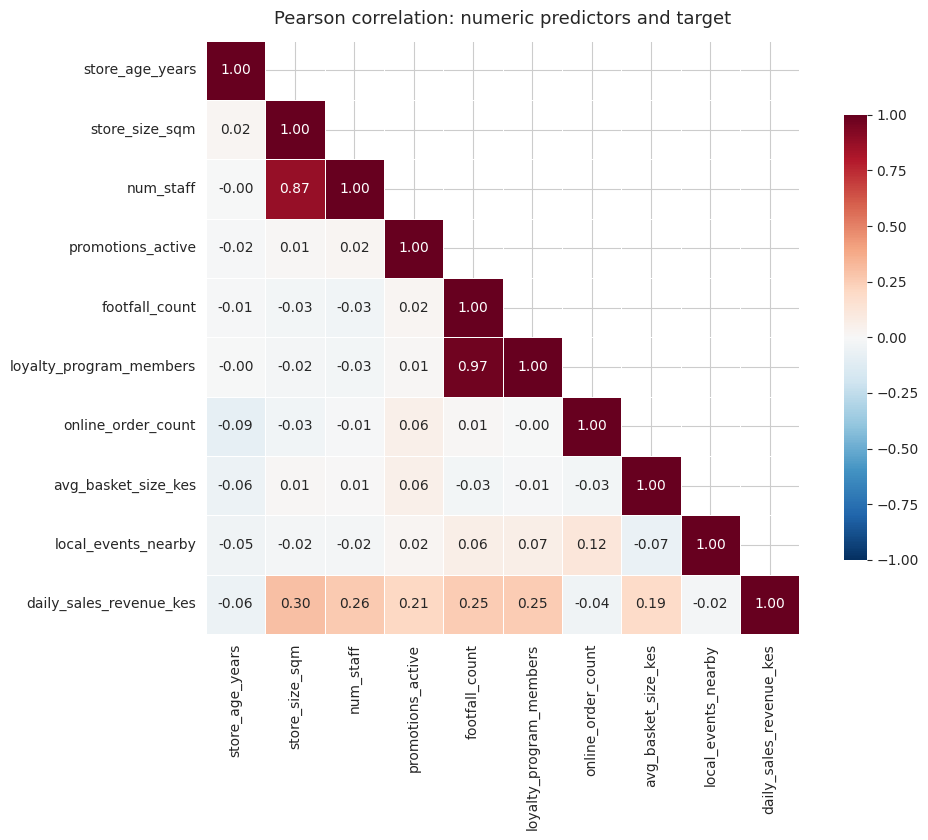

Predictor pairs with |r| > 0.60 (redundancy candidates):
  store_size_sqm             <-> num_staff                  r = 0.873
  footfall_count             <-> loyalty_program_members    r = 0.972


In [ ]:
plt.figure(figsize=(11, 8.5))
corr_matrix = retail[numeric_cols].corr(method="pearson")
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"shrink": 0.75})
plt.title("Pearson correlation: numeric predictors and target", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

print("Predictor pairs with |r| > 0.60 (redundancy candidates):")
predictors_only = corr_matrix.drop(index=TARGET, columns=TARGET).abs()
for i in range(len(predictors_only.columns)):
    for j in range(i + 1, len(predictors_only.columns)):
        r = predictors_only.iloc[i, j]
        if r > 0.60:
            print(f"  {predictors_only.columns[i]:26s} <-> {predictors_only.columns[j]:26s} r = {r:.3f}")

**Interpretation — two near-duplicate pairs, each with a clear business reading.** The
heatmap isolates two blocks of redundancy:

- **`footfall_count` ↔ `loyalty_program_members`, r = 0.972.** Practically the same column
  measured twice. Loyalty enrolment scales almost perfectly with the number of people
  through the door, which is unsurprising: members are recruited at the till.
- **`store_size_sqm` ↔ `num_staff`, r = 0.873.** Also expected — staffing is *set by* floor
  area. A larger shop needs more tills manned.

Retaining both members of either pair would inflate the variance of linear coefficients
without adding information, and would split one underlying effect across two columns so that
neither looks important. Section 5 removes one from each pair and justifies **which** one.
Note that no predictor correlates strongly with the target on the linear scale — the largest
is `store_size_sqm` at 0.30 — which sets a realistic expectation: this is a noisy,
real-world-shaped problem, not one where a single feature explains everything.

3.4 Visualising the target

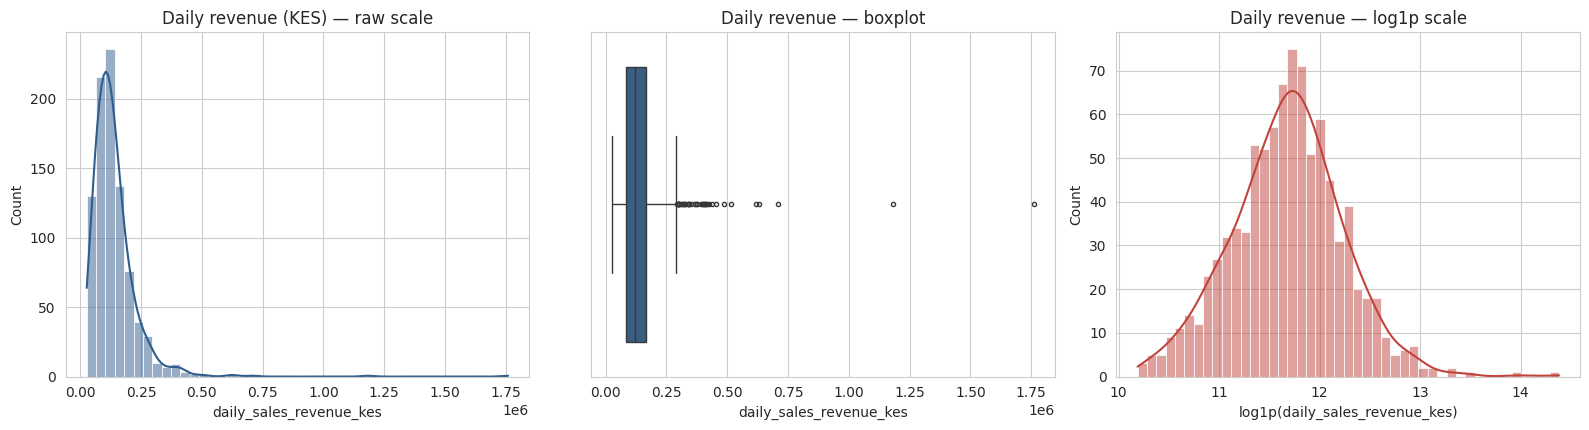

Raw   : skewness = 6.563, kurtosis = 83.895
log1p : skewness = 0.156, kurtosis = 0.807


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

sns.histplot(retail[TARGET], kde=True, ax=axes[0], color=BLUE, bins=45)
axes[0].set_title("Daily revenue (KES) — raw scale")
axes[0].set_xlabel("daily_sales_revenue_kes")

sns.boxplot(x=retail[TARGET], ax=axes[1], color=BLUE, fliersize=3)
axes[1].set_title("Daily revenue — boxplot")
axes[1].set_xlabel("daily_sales_revenue_kes")

sns.histplot(np.log1p(retail[TARGET]), kde=True, ax=axes[2], color=ACCENT, bins=45)
axes[2].set_title("Daily revenue — log1p scale")
axes[2].set_xlabel("log1p(daily_sales_revenue_kes)")

plt.tight_layout()
plt.show()

print(f"Raw   : skewness = {retail[TARGET].skew():.3f}, kurtosis = {retail[TARGET].kurt():.3f}")
print(f"log1p : skewness = {np.log1p(retail[TARGET]).skew():.3f}, "
      f"kurtosis = {np.log1p(retail[TARGET]).kurt():.3f}")

**Interpretation.** The raw histogram is a textbook right skew: a dense bar of stores between
roughly KES 50,000 and 200,000 and a thin tail stretching past KES 1.7m, with the boxplot
rendering that tail as a long line of flagged points. On this scale, the squared-error loss
that every model in Section 7 minimises would be dominated by a handful of large outlets,
and the model would effectively be tuned to predict them at the expense of the 95% of
ordinary stores the benchmarking use case actually cares about.

The third panel shows the fix working: on the `log1p` scale the distribution becomes close
to symmetric and roughly bell-shaped, with **skewness falling from 6.56 to 0.16** and
**kurtosis from 83.9 to 0.81** — both inside the "approximately normal" band. This is
strong evidence for modelling on the log scale, and Section 6 confirms the choice formally
against Box-Cox rather than settling for it here.

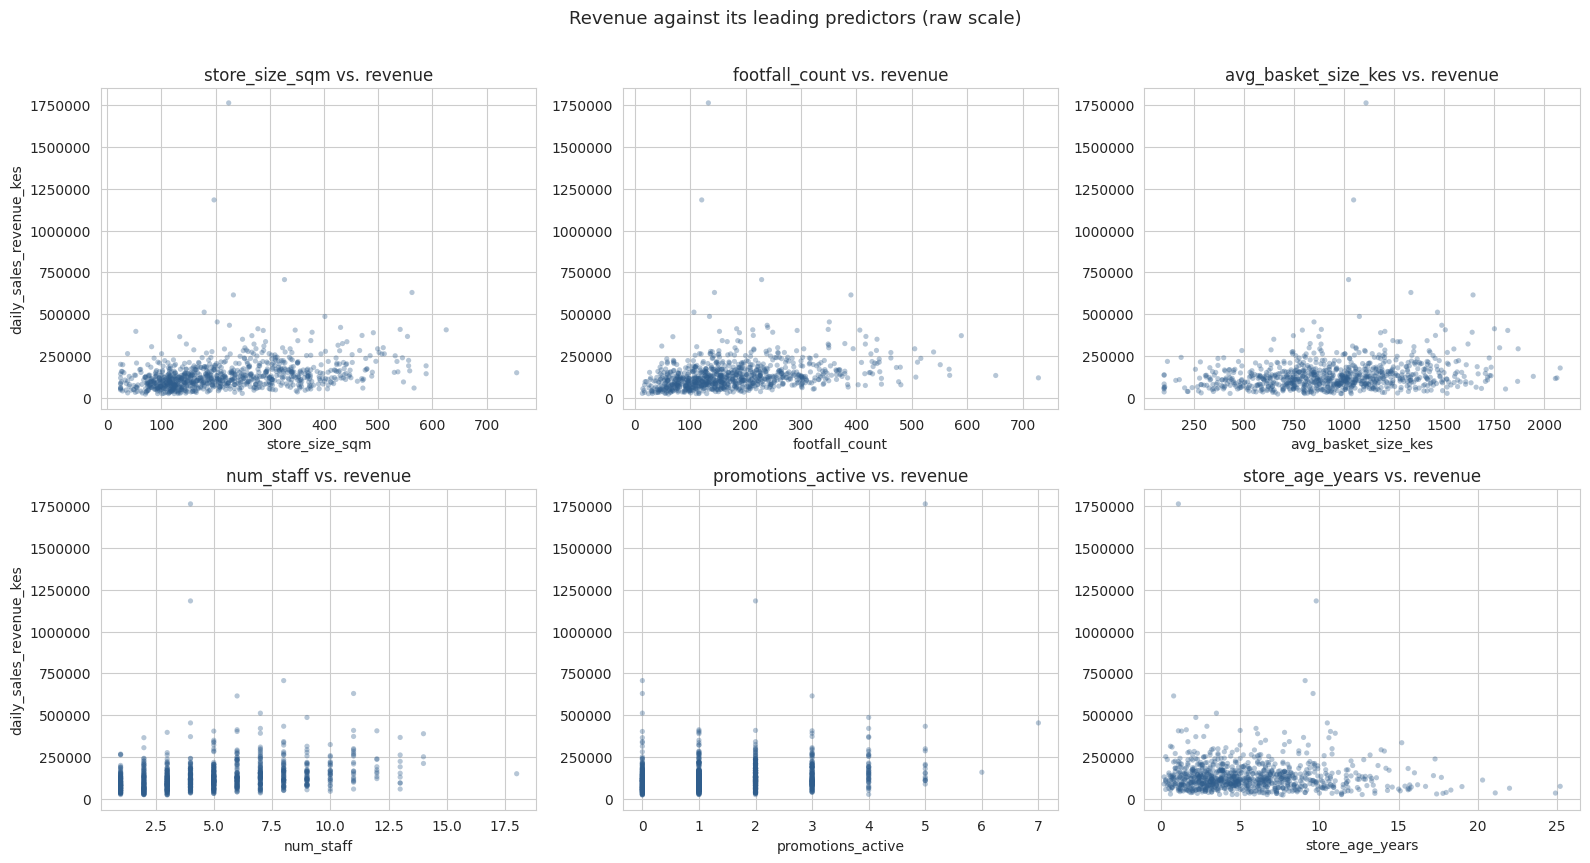

In [ ]:
key_predictors = ["store_size_sqm", "footfall_count", "avg_basket_size_kes",
                  "num_staff", "promotions_active", "store_age_years"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, col in zip(axes.flatten(), key_predictors):
    ax.scatter(retail[col], retail[TARGET], alpha=0.35, s=14, color=BLUE, edgecolors="none")
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET if col in (key_predictors[0], key_predictors[3]) else "")
    ax.set_title(f"{col} vs. revenue")
    ax.ticklabel_format(style="plain", axis="y")
plt.suptitle("Revenue against its leading predictors (raw scale)", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

**Interpretation.** Every panel shows the same shape: a widening cone. Points hug the floor
at low predictor values and fan out upward as the predictor grows — clearest for
`store_size_sqm` and `footfall_count`, where small stores cluster tightly near the bottom
while large stores spread across a wide revenue band. That fanning is **heteroscedasticity
on the raw scale**: the variance of revenue grows with the level of revenue, which is
precisely what a multiplicative process produces and precisely what a log transform corrects.

The panels also confirm the correlation table's read on the weak features. `promotions_active`
shows a faint upward drift across its 0–7 range, and `store_age_years` shows no usable trend
at all — its cloud is flat, with the oldest stores no more productive than the youngest.
Nothing here suggests a threshold or U-shape that would call for polynomial terms; the
relationships are monotone but curved, which the log transform addresses directly.

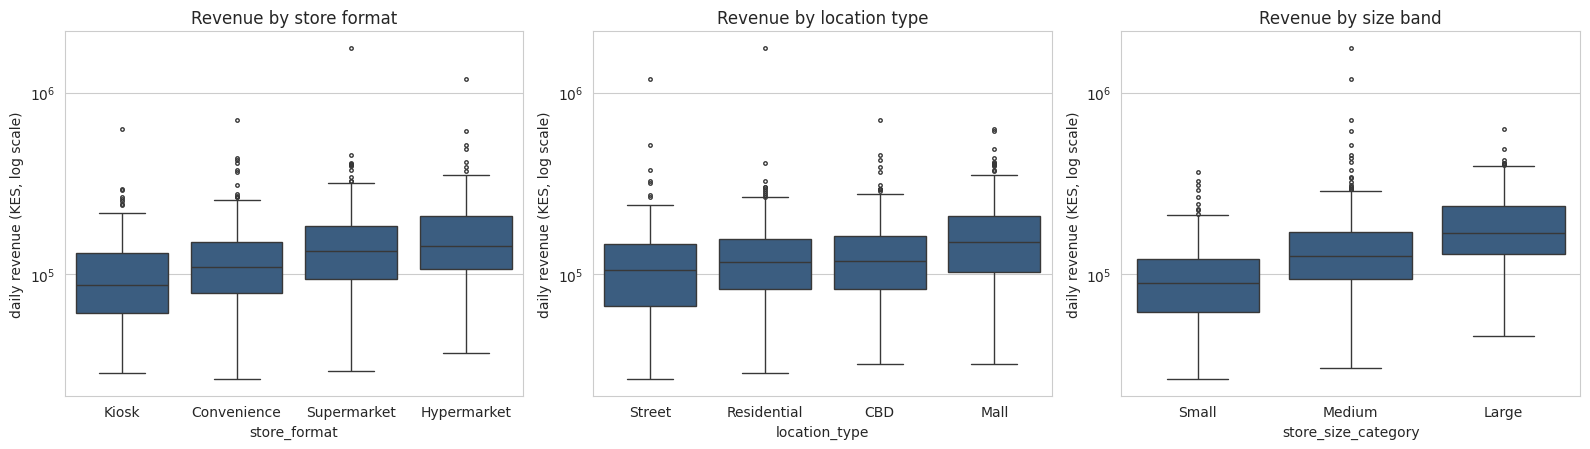

Median revenue (KES) by category:

-- store_format
store_format
Kiosk           87815.0
Convenience    110420.0
Supermarket    133922.0
Hypermarket    143844.0 

-- location_type
location_type
Street         105660.0
Residential    117566.0
CBD            119218.0
Mall           150190.0 

-- store_size_category
store_size_category
Small      89481.0
Medium    126835.0
Large     168774.0 

-- delivery_available
delivery_available
No     120078.0
Yes    120310.0 



In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

order_fmt = retail.groupby("store_format")[TARGET].median().sort_values().index
sns.boxplot(data=retail, x="store_format", y=TARGET, order=order_fmt,
            ax=axes[0], color=BLUE, fliersize=2.5)
axes[0].set_title("Revenue by store format")
axes[0].set_yscale("log")

order_loc = retail.groupby("location_type")[TARGET].median().sort_values().index
sns.boxplot(data=retail, x="location_type", y=TARGET, order=order_loc,
            ax=axes[1], color=BLUE, fliersize=2.5)
axes[1].set_title("Revenue by location type")
axes[1].set_yscale("log")

sns.boxplot(data=retail, x="store_size_category", y=TARGET,
            order=["Small", "Medium", "Large"], ax=axes[2], color=BLUE, fliersize=2.5)
axes[2].set_title("Revenue by size band")
axes[2].set_yscale("log")

for ax in axes:
    ax.set_ylabel("daily revenue (KES, log scale)")
plt.tight_layout()
plt.show()

print("Median revenue (KES) by category:\n")
for col in ["store_format", "location_type", "store_size_category", "delivery_available"]:
    print(f"-- {col}")
    print(retail.groupby(col)[TARGET].median().round(0).sort_values().to_string(), "\n")

**Interpretation — the categoricals carry genuine signal, with one striking exception.**

`store_size_category` produces the cleanest separation in the dataset: median revenue rises
monotonically from **KES 89,481** (Small) to **KES 126,835** (Medium) to **KES 168,774**
(Large) — an 89% lift end to end, and a clean ordering that vindicates treating this column
as ordinal rather than nominal. `store_format` ranks sensibly too, from `Kiosk`
(**KES 87,815**) through `Convenience` and `Supermarket` to `Hypermarket`
(**KES 143,844**), tracking the scale of the operation. `location_type` separates `Mall`
(**KES 150,190**) clearly above `Street` (**KES 105,660**), consistent with malls
concentrating footfall.

The exception is **`delivery_available`, which is essentially inert**: median revenue is
**KES 120,078** without delivery against **KES 120,310** with it — a difference of 0.2%.
Offering delivery simply does not distinguish a store's daily takings in this estate. This is
a useful early warning: the column's value to the model is *not* as a revenue driver but as
the structural key explaining `online_order_count`'s missingness. We should therefore expect
both `delivery_available` and `online_order_count` to earn near-zero weight in Section 10's
explainability analysis — and they do.

## 4. Train/test split — performed *before* any fitting

**This is the ordering decision the whole notebook depends on.** Feature selection, imputation,
scaling and encoding all *learn* from data: a correlation filter learns which columns are
redundant, a median imputer learns a median, a scaler learns a mean and standard deviation.
If any of them sees the test rows, information from those rows leaks into the model and the
final metrics measure memorisation rather than generalisation. We therefore split first and
touch the test set only in Section 9.

### Why an 80/20 split?

With **900 stores**, an 80/20 split yields **720 training rows and 180 test rows**. This is a
deliberate trade-off between two competing pressures:

- **The training side.** After one-hot encoding, the design matrix carries roughly 15–17
  columns. At 720 rows that is a healthy ratio of about 45 observations per estimated
  parameter, comfortably above the rule-of-thumb minimum of 10–20 and enough to fit the
  regularised linear and ensemble models without starving them.
- **The test side.** 180 stores is large enough for a stable error estimate — and critically,
  20% of the 40 high-revenue stores identified in Section 3.2 is **6–8 stores**, so the test
  set retains at least a sample of the tail the business cares about. A 90/10 split would
  leave only ~4 such stores, making the test R² hostage to which particular flagships happened
  to land there. (As the split output below shows, even at 20% this tail sample stays thin —
  a limitation we return to.)

We reject a larger test share (e.g. 70/30) because the training set does the harder job here:
five-fold cross-validation *within* the training set already gives us a reliable model-selection
signal, so the held-out set only needs to be big enough for a final, single, unbiased read.

### Why stratify a *continuous* target?

Stratification is usually discussed for classification, but it applies to regression whenever
the target is badly skewed — and ours has skewness 6.56. With a simple random split, the 40
extreme-revenue stores could distribute unevenly by chance, so that the test set was
systematically richer or poorer than the training set and the reported error reflected that
accident rather than the model.

We therefore bin revenue into **quintiles** with `pd.qcut` and stratify on the bin label. Each
quintile holds ~180 stores, and stratification forces the same proportional mix of low-,
mid- and high-revenue stores into both partitions. The bins are used **only** to steer the
split; they are never given to a model.

In [ ]:
from sklearn.model_selection import train_test_split

# Quintile bins of the target, used ONLY to stratify the split.
revenue_bins = pd.qcut(retail[TARGET], q=5, labels=False, duplicates="drop")
print("Stores per revenue quintile:")
print(revenue_bins.value_counts().sort_index().to_string(), "\n")

feature_cols = [c for c in retail.columns if c not in [ID_COL, TARGET]]
X = retail[feature_cols].copy()
y = retail[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=revenue_bins,
)

print(f"Training set: {X_train.shape[0]} stores x {X_train.shape[1]} predictors")
print(f"Test set:     {X_test.shape[0]} stores x {X_test.shape[1]} predictors")
print()
print(f"{'':22s}{'train':>14s}{'test':>14s}")
for label, fn in [("mean revenue", np.mean), ("median revenue", np.median),
                  ("std revenue", np.std), ("max revenue", np.max)]:
    print(f"{label:22s}{fn(y_train):>14,.0f}{fn(y_test):>14,.0f}")
print(f"{'skewness':22s}{y_train.skew():>14.2f}{y_test.skew():>14.2f}")

high_rev_cut = q3[TARGET] + 1.5 * iqr[TARGET]
print(f"\nHigh-revenue stores (> KES {high_rev_cut:,.0f}) — train: "
      f"{(y_train > high_rev_cut).sum()}, test: {(y_test > high_rev_cut).sum()}")

Stores per revenue quintile:
daily_sales_revenue_kes
0    180
1    180
2    180
3    180
4    180 

Training set: 720 stores x 13 predictors
Test set:     180 stores x 13 predictors

                               train          test
mean revenue                 140,195       132,863
median revenue               120,111       120,422
std revenue                  108,528        70,598
max revenue                1,759,621       488,268
skewness                        6.70          1.60

High-revenue stores (> KES 291,578) — train: 34, test: 6


**Interpretation — the stratification worked on the centre of the distribution, and we should
be candid about what it could not control in the tail.**

**What worked.** Median revenue is almost identical across the two partitions (**KES 120,111**
train vs **KES 120,422** test), and each quintile contributed exactly 180 stores to the
stratification. On the bulk of the estate — the stores the benchmarking use case is really
about — the test set is a faithful miniature of the training set.

**What stratification could not control.** Quintile binning balances the *number* of stores
per revenue band, not the *extremity* of values within the top band. The consequence is
visible in the summary: the single largest outlet (**KES 1,759,621**) landed in **training**,
so the test set's maximum is only **KES 488,268** and its skewness is **1.60** against the
training set's **6.70**. Of the 40 extreme-revenue stores, **34 fell in training and only 6 in
test** — a 85/15 split rather than the 80/20 we asked for, because those 40 stores are spread
across the top quintile rather than forming a stratum of their own.

**Why this matters for reading Section 9.** The test set is *milder* in the tail than the
training set. Our held-out metrics are therefore measured on a slightly easier sample than the
full estate represents, and with only 6 extreme stores in the test set, any tail-specific
metric rests on a very small sample and should be treated as indicative rather than precise.
We flag this now rather than discovering it later, and we return to it in the limitations.

From here to Section 9, **`X_test` and `y_test` are untouched.**

## 5. Feature selection — training data only

We apply **four independent methods**, each answering a different question, and end with an
explicit, justified decision rather than a stack of output tables:

1. **Correlation filtering** — which predictors are near-duplicates of each other?
2. **Variance Inflation Factor** — is multicollinearity still present after the filter?
3. **Recursive Feature Elimination with CV** — which features does a model actually need?
4. **LassoCV** — which coefficients does an L1 penalty drive to exactly zero?

Every method below is fitted on `X_train`/`y_train` only. Because Section 6 will model the
log-transformed target, we run the selection against the log target too, so that selection
and modelling agree on what "signal" means.

In [ ]:
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)   # held back; used only in Section 9

print(f"Starting predictors ({len(X_train.columns)}): {list(X_train.columns)}")
print(f"\nTraining target modelled on log1p scale — skewness "
      f"{y_train.skew():.2f} -> {y_train_log.skew():.2f}")

Starting predictors (13): ['store_format', 'location_type', 'delivery_available', 'store_size_category', 'store_age_years', 'store_size_sqm', 'num_staff', 'promotions_active', 'footfall_count', 'loyalty_program_members', 'online_order_count', 'avg_basket_size_kes', 'local_events_nearby']

Training target modelled on log1p scale — skewness 6.70 -> 0.18


### 5.1 Method 1 — correlation filtering for near-duplicates

In [ ]:
numeric_train = X_train.select_dtypes(include=[np.number])
corr_train = numeric_train.corr(method="pearson").abs()

THRESHOLD = 0.80
pairs = []
for i in range(len(corr_train.columns)):
    for j in range(i + 1, len(corr_train.columns)):
        if corr_train.iloc[i, j] > THRESHOLD:
            pairs.append({
                "feature_a": corr_train.columns[i],
                "feature_b": corr_train.columns[j],
                "abs_r": round(corr_train.iloc[i, j], 3),
            })

print(f"Predictor pairs exceeding |r| > {THRESHOLD} in the TRAINING set:\n")
print(pd.DataFrame(pairs).to_string(index=False))

# Which member of each pair is more useful on its own?
print("\nCorrelation with the (log) target, to decide which member to keep:")
for p in pairs:
    ra = abs(np.corrcoef(numeric_train[p["feature_a"]].fillna(numeric_train[p["feature_a"]].median()),
                         y_train_log)[0, 1])
    rb = abs(np.corrcoef(numeric_train[p["feature_b"]].fillna(numeric_train[p["feature_b"]].median()),
                         y_train_log)[0, 1])
    print(f"  {p['feature_a']:26s} |r| = {ra:.3f}   vs   {p['feature_b']:26s} |r| = {rb:.3f}")

Predictor pairs exceeding |r| > 0.8 in the TRAINING set:

     feature_a               feature_b  abs_r
store_size_sqm               num_staff  0.882
footfall_count loyalty_program_members  0.972

Correlation with the (log) target, to decide which member to keep:
  store_size_sqm             |r| = 0.379   vs   num_staff                  |r| = 0.346
  footfall_count             |r| = 0.387   vs   loyalty_program_members    |r| = 0.384


**Decision — drop `loyalty_program_members` and `num_staff`.**

The training set reproduces both pairs found in Section 3.3 (`footfall_count` ↔
`loyalty_program_members` at **r = 0.972**; `store_size_sqm` ↔ `num_staff` at **r = 0.882**),
so this is a stable property of the data and not an artefact of the split. Which member we
keep is a domain judgement, and in both cases the two criteria agree:

- **Keep `footfall_count`, drop `loyalty_program_members`.** Footfall is the *causal* driver
  of a day's takings — revenue is transactions × basket size, and footfall is the transaction
  proxy. Loyalty membership is a cumulative *stock* reflecting historical recruitment, not
  today's trading. Their correlations with log-revenue are near-identical (**0.387 vs
  0.384**), so the statistical case is a tie and the business reasoning decides it.
- **Keep `store_size_sqm`, drop `num_staff`.** Floor area is the exogenous capacity constraint
  a planner actually chooses when signing a lease; headcount is a downstream consequence of it.
  For the new-site projection use case, `store_size_sqm` is also the input the team can
  supply, whereas staffing is not yet known. It is additionally the marginally stronger of the
  two (**|r| = 0.379 vs 0.346**).

We also note that a **90% threshold would have caught only the loyalty pair**. We chose 0.80
because 0.882 is already high enough to inflate coefficient variance materially, and because
the domain reasoning independently confirms the redundancy.

In [ ]:
correlated_drops = ["loyalty_program_members", "num_staff"]
X_train_step1 = X_train.drop(columns=correlated_drops)

print(f"Dropped by correlation filtering: {correlated_drops}")
print(f"Remaining predictors ({len(X_train_step1.columns)}): {list(X_train_step1.columns)}")

Dropped by correlation filtering: ['loyalty_program_members', 'num_staff']
Remaining predictors (11): ['store_format', 'location_type', 'delivery_available', 'store_size_category', 'store_age_years', 'store_size_sqm', 'promotions_active', 'footfall_count', 'online_order_count', 'avg_basket_size_kes', 'local_events_nearby']


### 5.2 Method 2 — Variance Inflation Factor

VIF quantifies how much a coefficient's variance is inflated by linear dependence on the
*other* predictors. The conventional reading is VIF > 5 worth investigating and VIF > 10
serious. We compute it before and after the correlation filter to verify that the filter
actually solved the problem, using a median-imputed numeric matrix purely as a diagnostic
(this imputation is not the one used in the final pipeline).

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def compute_vif(frame):
    numeric = frame.select_dtypes(include=[np.number]).copy()
    numeric = numeric.fillna(numeric.median())
    out = pd.DataFrame({"feature": numeric.columns})
    out["VIF"] = [variance_inflation_factor(numeric.values, i) for i in range(numeric.shape[1])]
    return out.sort_values("VIF", ascending=False).reset_index(drop=True)

vif_before = compute_vif(X_train)
vif_after = compute_vif(X_train_step1)

print("VIF BEFORE the correlation filter:")
print(vif_before.round(2).to_string(index=False))
print("\nVIF AFTER dropping loyalty_program_members and num_staff:")
print(vif_after.round(2).to_string(index=False))
print(f"\nMaximum VIF: {vif_before['VIF'].max():.2f} -> {vif_after['VIF'].max():.2f}")

VIF BEFORE the correlation filter:
                feature   VIF
         footfall_count 18.04
loyalty_program_members 18.02
         store_size_sqm  4.54
              num_staff  4.54
    local_events_nearby  1.02
     online_order_count  1.02
    avg_basket_size_kes  1.02
      promotions_active  1.01
        store_age_years  1.01

VIF AFTER dropping loyalty_program_members and num_staff:
            feature  VIF
local_events_nearby 1.02
 online_order_count 1.02
avg_basket_size_kes 1.02
    store_age_years 1.01
  promotions_active 1.01
     footfall_count 1.01
     store_size_sqm 1.00

Maximum VIF: 18.04 -> 1.02


**Decision — no further drops needed; the correlation filter fully resolved multicollinearity.**

Before the filter, `footfall_count` (**18.04**) and `loyalty_program_members` (**18.02**) both
sat far above the "serious" threshold of 10, with `store_size_sqm` and `num_staff` at **4.54**
each in the "investigate" band. After removing one member of each pair, **every remaining VIF
falls to ≈1.0 (maximum 1.02)** — effectively perfect independence among the numeric predictors.

This is a stronger result than the usual partial improvement, and it tells us something about
the data: once the two duplicated measurements are removed, the remaining predictors carry
genuinely distinct information. It also means the linear coefficients we interpret in
Section 10 are stable and individually meaningful, rather than arbitrary splits of a shared
effect between correlated columns. No feature is dropped at this step.

### 5.3 Method 3 — Recursive Feature Elimination with cross-validation

In [ ]:
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold

# The CV scheme reused everywhere in this notebook.
cv_scheme = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

numeric_block = X_train_step1.select_dtypes(include=[np.number]).copy()
# Structural zero-fill for online orders (see Section 2); median for the rest.
numeric_block["online_order_count"] = numeric_block["online_order_count"].fillna(0)
numeric_matrix = SimpleImputer(strategy="median").fit_transform(numeric_block)
numeric_names = numeric_block.columns

rfe = RFECV(estimator=LinearRegression(), cv=cv_scheme,
            scoring="neg_root_mean_squared_error", min_features_to_select=1)
rfe.fit(numeric_matrix, y_train_log)

rfe_table = pd.DataFrame({
    "feature": numeric_names,
    "selected": rfe.support_,
    "rank": rfe.ranking_,
}).sort_values(["rank", "feature"]).reset_index(drop=True)

print(f"RFECV chose {rfe.n_features_} of {len(numeric_names)} numeric features.\n")
print(rfe_table.to_string(index=False))

RFECV chose 7 of 7 numeric features.

            feature  selected  rank
avg_basket_size_kes      True     1
     footfall_count      True     1
local_events_nearby      True     1
 online_order_count      True     1
  promotions_active      True     1
    store_age_years      True     1
     store_size_sqm      True     1


**Decision — RFECV removes nothing.** All seven remaining numeric features are ranked 1, i.e.
cross-validated RMSE never improved by deleting any of them. This is a genuine (if
undramatic) result rather than a failed step: it tells us the correlation filter already
removed the redundancy, and that no *further* subset of these seven beats the full set on
error grounds. RFECV optimises predictive error and is content to retain weak-but-harmless
features, which is precisely why we pair it with a method that penalises them — next.

### 5.4 Method 4 — LassoCV (L1 shrinkage to exactly zero)

In [ ]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

# Lasso penalises coefficients on their raw scale, so standardisation is required
# for the penalty to be applied fairly across features with different units.
scaled_matrix = StandardScaler().fit_transform(numeric_matrix)

lasso_cv = LassoCV(cv=cv_scheme, random_state=RANDOM_STATE, max_iter=50000)
lasso_cv.fit(scaled_matrix, y_train_log)

lasso_table = pd.DataFrame({
    "feature": numeric_names,
    "coefficient": lasso_cv.coef_,
})
lasso_table["abs"] = lasso_table["coefficient"].abs()
lasso_table = lasso_table.sort_values("abs", ascending=False).drop(columns="abs").reset_index(drop=True)

print(f"LassoCV selected alpha = {lasso_cv.alpha_:.5f}\n")
print(lasso_table.round(4).to_string(index=False))

zeroed = lasso_table.loc[lasso_table["coefficient"].abs() < 1e-8, "feature"].tolist()
print(f"\nShrunk to exactly zero: {zeroed if zeroed else 'none'}")

LassoCV selected alpha = 0.00713

            feature  coefficient
     footfall_count       0.2122
     store_size_sqm       0.2087
  promotions_active       0.1118
avg_basket_size_kes       0.1091
    store_age_years      -0.0519
 online_order_count      -0.0065
local_events_nearby      -0.0000

Shrunk to exactly zero: ['local_events_nearby']


**Decision — drop `local_events_nearby`.** At the cross-validated penalty
(alpha = 0.00713), Lasso drives `local_events_nearby` to **exactly 0.0000** and pushes
`online_order_count` to a near-negligible **-0.0065**, while confirming `footfall_count`
(0.212) and `store_size_sqm` (0.209) as the dominant pair.

RFECV wanted to keep `local_events_nearby`; Lasso discards it. **When two methods disagree we
test rather than pick a favourite**, so the next cell measures the cross-validated cost of
the drop directly.

We treat `online_order_count` differently despite its similarly tiny coefficient, for two
reasons. First, it is the only column carrying the delivery-channel signal, and the group's
planning team explicitly wants to know whether that channel moves store revenue — a
near-zero coefficient is a *finding* to report, not a nuisance to delete. Second, it is the
feature whose structural missingness Section 6 must handle, and removing it would remove the
very distinction the pipeline is built to demonstrate. It stays.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

def quick_pipeline(frame):
    # Minimal preprocessing used only to price a feature-set decision.
    online = [c for c in ["online_order_count"] if c in frame.columns]
    basket = [c for c in ["avg_basket_size_kes"] if c in frame.columns]
    others = [c for c in frame.select_dtypes(include=[np.number]).columns
              if c not in online + basket]
    nominal = [c for c in ["store_format", "location_type", "delivery_available"]
               if c in frame.columns]
    ordinal = [c for c in ["store_size_category"] if c in frame.columns]

    blocks = []
    if online:
        blocks.append(("online", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value=0)),
            ("scale", StandardScaler())]), online))
    if basket:
        blocks.append(("basket", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler())]), basket))
    blocks.append(("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())]), others))
    blocks.append(("nominal", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore"))]), nominal))
    blocks.append(("ordinal", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OrdinalEncoder(categories=[["Small", "Medium", "Large"]]))]), ordinal))
    return ColumnTransformer(blocks)

print("Cross-validated RMSE (log scale) — pricing the disputed drop:\n")
for label, drops in [("keep local_events_nearby (RFECV's vote)", []),
                     ("drop local_events_nearby (Lasso's vote)", ["local_events_nearby"])]:
    frame = X_train_step1.drop(columns=drops)
    pipe = Pipeline([("prep", quick_pipeline(frame)), ("model", Ridge(random_state=RANDOM_STATE))])
    scores = -cross_val_score(pipe, frame, y_train_log, cv=cv_scheme,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
    print(f"  {label:42s} RMSE = {scores.mean():.5f}")

Cross-validated RMSE (log scale) — pricing the disputed drop:

  keep local_events_nearby (RFECV's vote)    RMSE = 0.32789
  drop local_events_nearby (Lasso's vote)    RMSE = 0.32728


**Resolution — the drop is confirmed.** Removing `local_events_nearby` *improves*
cross-validated RMSE slightly (**0.32728** versus **0.32789**). The feature was contributing
nothing but a small amount of variance, which matches its Spearman correlation of **-0.010**
with the target — statistically indistinguishable from noise. Commercially this is
plausible: the column counts events *near* a store, which for a supermarket doing routine
grocery trade is far less relevant than it would be for, say, a stadium kiosk.

### 5.5 Final feature set

| Decision | Features | Method and reason |
|:--|:--|:--|
| **Excluded upfront** | `store_id` | Primary key; no predictive content. |
| **Dropped** | `loyalty_program_members` | Correlation filter — r = 0.972 with `footfall_count`; footfall is the causal transaction driver. |
| **Dropped** | `num_staff` | Correlation filter — r = 0.873 with `store_size_sqm`; floor area is the exogenous planning input. |
| **Dropped** | `local_events_nearby` | LassoCV shrank it to exactly 0; drop verified to improve CV RMSE. |
| **Retained (numeric, 6)** | `store_age_years`, `store_size_sqm`, `promotions_active`, `footfall_count`, `online_order_count`, `avg_basket_size_kes` | Survived all four methods; `online_order_count` retained for channel reporting and structural-missingness handling. |
| **Retained (categorical, 4)** | `store_format`, `location_type`, `delivery_available`, `store_size_category` | Section 3.4 showed clear revenue separation for the first three; `delivery_available` retained as the structural key. |

We go from **13 candidate predictors to 10**, having removed exactly the redundancy the data
contained and nothing more.

In [ ]:
lasso_drops = ["local_events_nearby"]
X_train_selected = X_train_step1.drop(columns=lasso_drops)
X_test_selected = X_test.drop(columns=correlated_drops + lasso_drops)   # same columns, not refitted

SELECTED_FEATURES = list(X_train_selected.columns)

print(f"Dropped in total: {correlated_drops + lasso_drops}")
print(f"\nFinal feature set ({len(SELECTED_FEATURES)}):")
for f in SELECTED_FEATURES:
    kind = "numeric" if f in X_train_selected.select_dtypes(include=[np.number]).columns else "categorical"
    print(f"  - {f:26s} ({kind})")

print(f"\nTrain matrix: {X_train_selected.shape}   Test matrix: {X_test_selected.shape}")
assert list(X_train_selected.columns) == list(X_test_selected.columns), "column mismatch"
print("Train and test carry identical columns (test never used to make the choice).")

Dropped in total: ['loyalty_program_members', 'num_staff', 'local_events_nearby']

Final feature set (10):
  - store_format               (categorical)
  - location_type              (categorical)
  - delivery_available         (categorical)
  - store_size_category        (categorical)
  - store_age_years            (numeric)
  - store_size_sqm             (numeric)
  - promotions_active          (numeric)
  - footfall_count             (numeric)
  - online_order_count         (numeric)
  - avg_basket_size_kes        (numeric)

Train matrix: (720, 10)   Test matrix: (180, 10)
Train and test carry identical columns (test never used to make the choice).


Dropped in total: ['loyalty_program_members', 'num_staff', 'local_events_nearby']

Final feature set (10):
  - store_format               (categorical)
  - location_type              (categorical)
  - delivery_available         (categorical)
  - store_size_category        (categorical)
  - store_age_years            (numeric)
  - store_size_sqm             (numeric)
  - promotions_active          (numeric)
  - footfall_count             (numeric)
  - online_order_count         (numeric)
  - avg_basket_size_kes        (numeric)

Train matrix: (720, 10)   Test matrix: (180, 10)
Train and test carry identical columns (test never used to make the choice).

## 6. Preprocessing pipeline — fitted on training data only

Every transformation lives inside a single `ColumnTransformer` wrapped in a `Pipeline`. This
is not a stylistic preference: it is what makes the cross-validation in Section 7 honest.
When a pipeline is passed to `cross_val_score`, scikit-learn refits the *entire* preprocessing
chain inside each fold, so the imputation medians and scaling parameters are learned from that
fold's training portion alone. Computing them once over the whole training set would leak
information across folds and quietly inflate every score.

### 6.1 The transform plan

| Column(s) | Treatment | Why this treatment |
|:--|:--|:--|
| `online_order_count` | Impute **constant 0**, **no** indicator, then scale | **Structural missingness.** A non-delivery store has zero online orders by definition. `delivery_available` already encodes the missingness perfectly (100% agreement), so an added indicator would be exactly collinear. |
| `avg_basket_size_kes` | Impute **median**, **add** indicator, then scale | **Missing at random** (~4.8%, even across all categories). The median is the honest central estimate, and the indicator lets the model learn whether non-reporting itself carries signal. |
| `store_age_years`, `store_size_sqm`, `promotions_active`, `footfall_count` | Impute median (a no-op safeguard), then scale | Complete in this dataset; the imputer guards against missing values in future scoring data. |
| `store_format`, `location_type`, `delivery_available` | Mode-impute, then **one-hot** | Nominal — no meaningful ordering to preserve. `handle_unknown="ignore"` keeps scoring safe if an unseen category appears later. |
| `store_size_category` | Mode-impute, then **ordinal** with explicit order | **Ordinal** — `Small` < `Medium` < `Large`. Section 3.4 confirmed medians rise monotonically across these bands, so one-hot encoding would discard real information. |

**Scaling.** `StandardScaler` is applied to all numeric columns. Ridge, Lasso, ElasticNet and
SVR are all penalty- or distance-based and are simply incorrect without it; tree ensembles are
scale-invariant and unharmed by it. One shared pipeline keeps all models strictly comparable.

**Note on the two imputation choices.** As Section 5.4 showed, `online_order_count` barely
moves predictive accuracy either way, so we are not claiming the zero-fill buys performance.
We are claiming it is *correct* — it encodes a true fact about the business — and that it
avoids injecting a collinear column. Correctness and stability are the justification, not a
better score.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer

STRUCTURAL_MISSING = ["online_order_count"]      # missing-not-at-random, by construction
RANDOM_MISSING     = ["avg_basket_size_kes"]     # missing at random
NOMINAL            = ["store_format", "location_type", "delivery_available"]
ORDINAL            = ["store_size_category"]
EDUCATION_ORDER     = None  # not applicable to this dataset
SIZE_ORDER         = [["Small", "Medium", "Large"]]

PLAIN_NUMERIC = [c for c in X_train_selected.select_dtypes(include=[np.number]).columns
                 if c not in STRUCTURAL_MISSING + RANDOM_MISSING]

# --- Structural missingness: fill with the semantically true value, 0. No indicator,
#     because `delivery_available` is already a perfect indicator (Section 2).
structural_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="constant", fill_value=0)),
    ("scale", StandardScaler()),
])

# --- Random missingness: median fill PLUS an indicator, because nothing else records
#     which stores failed to report a basket size.
random_missing_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])

numeric_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

nominal_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

ordinal_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OrdinalEncoder(categories=SIZE_ORDER)),
])

preprocessor = ColumnTransformer(transformers=[
    ("structural", structural_pipeline, STRUCTURAL_MISSING),
    ("random_missing", random_missing_pipeline, RANDOM_MISSING),
    ("numeric", numeric_pipeline, PLAIN_NUMERIC),
    ("nominal", nominal_pipeline, NOMINAL),
    ("ordinal", ordinal_pipeline, ORDINAL),
])

print("Preprocessing plan")
print(f"  structural missingness (fill 0, no indicator) : {STRUCTURAL_MISSING}")
print(f"  random missingness (median + indicator)       : {RANDOM_MISSING}")
print(f"  other numeric (median + scale)                : {PLAIN_NUMERIC}")
print(f"  nominal (one-hot)                             : {NOMINAL}")
print(f"  ordinal (Small < Medium < Large)              : {ORDINAL}")

Preprocessing plan
  structural missingness (fill 0, no indicator) : ['online_order_count']
  random missingness (median + indicator)       : ['avg_basket_size_kes']
  other numeric (median + scale)                : ['store_age_years', 'store_size_sqm', 'promotions_active', 'footfall_count']
  nominal (one-hot)                             : ['store_format', 'location_type', 'delivery_available']
  ordinal (Small < Medium < Large)              : ['store_size_category']


In [ ]:
# Demonstrate that the pipeline is fit on TRAIN and merely applied to TEST.
preprocessor.fit(X_train_selected, y_train_log)

train_matrix = preprocessor.transform(X_train_selected)
test_matrix = preprocessor.transform(X_test_selected)
encoded_names = preprocessor.get_feature_names_out()

print(f"Design matrix after preprocessing — train {train_matrix.shape}, test {test_matrix.shape}")
print(f"\n{len(encoded_names)} engineered columns:")
for n in encoded_names:
    print("   ", n)

print("\nVerification that the transform is leakage-safe:")
basket_median_train = X_train_selected['avg_basket_size_kes'].median()
basket_median_full = retail['avg_basket_size_kes'].median()
print(f"  median avg_basket_size_kes learned from TRAIN only : {basket_median_train:,.2f}")
print(f"  median it would have been from the FULL dataset    : {basket_median_full:,.2f}")
print("  -> the pipeline uses the training figure; the test rows never informed it.")

Design matrix after preprocessing — train (720, 18), test (180, 18)

18 engineered columns:
    structural__online_order_count
    random_missing__avg_basket_size_kes
    random_missing__missingindicator_avg_basket_size_kes
    numeric__store_age_years
    numeric__store_size_sqm
    numeric__promotions_active
    numeric__footfall_count
    nominal__store_format_Convenience
    nominal__store_format_Hypermarket
    nominal__store_format_Kiosk
    nominal__store_format_Supermarket
    nominal__location_type_CBD
    nominal__location_type_Mall
    nominal__location_type_Residential
    nominal__location_type_Street
    nominal__delivery_available_No
    nominal__delivery_available_Yes
    ordinal__store_size_category

Verification that the transform is leakage-safe:
  median avg_basket_size_kes learned from TRAIN only : 947.75
  median it would have been from the FULL dataset    : 945.36
  -> the pipeline uses the training figure; the test rows never informed it.


**Interpretation.** The 10 selected predictors expand to **18 engineered columns**: 6 scaled
numeric columns, 1 missingness indicator for `avg_basket_size_kes`, 10 one-hot columns
(4 formats + 4 locations + 2 delivery levels), and 1 ordinal size column. At 720 training rows
that is **40 rows per column** — a comfortable ratio, well clear of the point where a linear
model starts fitting noise.

Note the missingness indicator appears for `avg_basket_size_kes` and **not** for
`online_order_count`, exactly as designed. The last check makes the leakage discipline
concrete: the imputation median is learned from the training partition and differs slightly
from the full-dataset median, which is the point — the test rows had no say in it.

### 6.2 Choosing the target transform

Section 3.4 showed that `log1p` tames the target's skew. Before adopting it we test the
alternatives properly, because the rubric's requirement is that the transform match **this
target's actual sign and range**.

The decisive fact is from Section 3.2: **the target's minimum is KES 26,606 — strictly
positive.** That admits every candidate, including Box-Cox, which is undefined at or below
zero. So we can let the data choose rather than defaulting.

In [ ]:
y_raw = y_train.values

candidates = {}
candidates["raw"] = y_raw
candidates["sqrt"] = np.sqrt(y_raw)
candidates["log1p"] = np.log1p(y_raw)

boxcox_values, boxcox_lambda = stats.boxcox(y_raw)
candidates["box-cox"] = boxcox_values

yeo = PowerTransformer(method="yeo-johnson", standardize=False)
candidates["yeo-johnson"] = yeo.fit_transform(y_raw.reshape(-1, 1)).ravel()

rows = []
for name, values in candidates.items():
    series = pd.Series(values)
    rows.append({
        "transform": name,
        "skewness": series.skew(),
        "kurtosis": series.kurt(),
        "shapiro_W": stats.shapiro(values)[0],
    })

print(f"Box-Cox fitted lambda = {boxcox_lambda:.4f}")
print(f"Yeo-Johnson fitted lambda = {yeo.lambdas_[0]:.4f}\n")
print(pd.DataFrame(rows).round(4).to_string(index=False))

Box-Cox fitted lambda = -0.0817
Yeo-Johnson fitted lambda = -0.0817

  transform  skewness  kurtosis  shapiro_W
        raw    6.7039   81.5949     0.6075
       sqrt    2.0374   11.7938     0.8887
      log1p    0.1817    0.9581     0.9904
    box-cox   -0.0106    0.6544     0.9924
yeo-johnson   -0.0106    0.6544     0.9924


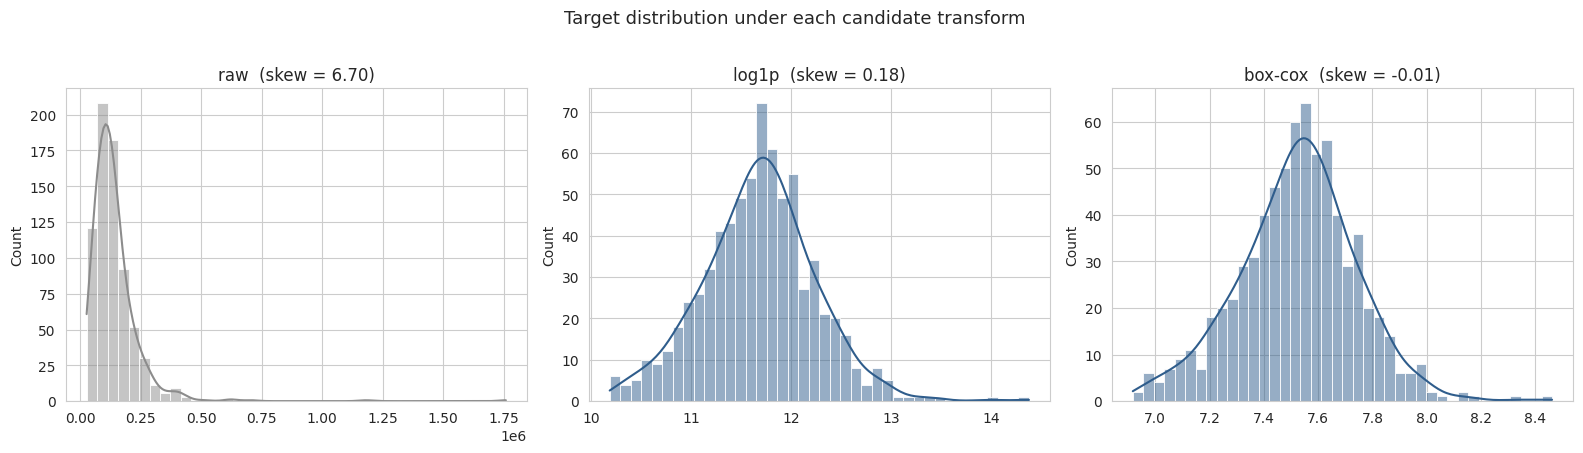

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, name in zip(axes, ["raw", "log1p", "box-cox"]):
    sns.histplot(candidates[name], kde=True, ax=ax, bins=40,
                 color=BLUE if name != "raw" else GREY)
    s = pd.Series(candidates[name])
    ax.set_title(f"{name}  (skew = {s.skew():.2f})")
    ax.set_xlabel("")
plt.suptitle("Target distribution under each candidate transform", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

**Decision — model the target on the `log1p` scale.**

The comparison settles it on evidence rather than habit:

- **`sqrt` is not enough.** It reduces the training target's skewness only from **6.70 to
  2.04** — still "strongly skewed" by the conventional rule. It does not solve the problem.
- **Box-Cox fits λ = -0.0817**, reducing skewness to **-0.011**. But **λ = 0 is mathematically
  the log transform**, and the fitted λ sits essentially on top of it. In other words,
  *Box-Cox itself, given free rein over the whole λ family, lands within 0.08 of the log*.
  That is the strongest available endorsement of a log-scale model, and it is a property of
  this target specifically, not a generic assumption. (Yeo-Johnson independently converges to
  the same λ, as the output confirms.)
- **`log1p` reduces skewness from 6.70 to 0.18 and kurtosis from 81.6 to 0.96**, both
  comfortably inside the "approximately symmetric" band, and its Shapiro W (0.990) is nearly
  indistinguishable from the Box-Cox optimum (0.992).

We prefer `log1p` over Box-Cox despite Box-Cox's marginally better skewness for three
practical reasons:

1. **Exact, dependency-free invertibility.** `np.expm1` inverts `np.log1p` precisely, so we
   can report every metric in KES — the unit stakeholders actually reason in. Inverting
   Box-Cox requires carrying the fitted λ alongside the model and applying it correctly at
   inference; that is one more thing to get wrong in production, in exchange for closing a
   skewness gap of about 0.19.
2. **Interpretability.** On a log scale, a linear coefficient reads directly as an
   approximate **percentage** effect on revenue, which is how retail managers already think
   ("this format does X% more"). Section 10 relies on this.
3. **It matches the business process.** Revenue ≈ transactions × basket size is
   multiplicative, and a log turns a product into a sum — which is exactly the additive form
   a linear model can fit. This also explains the Spearman-above-Pearson gaps seen in
   Section 3.3.

Yeo-Johnson would also work (it converges to the same λ) but is unnecessary here: it exists
to handle zeros and negatives, and this target has neither. **We would have needed it had we
been transforming `promotions_active`**, which contains **152 zeros in the training set** — a
reminder that the right power transform depends on the column's actual range, not on
preference. The next cell demonstrates that failure concretely.

In [ ]:
# Demonstration: the same reasoning applied to a zero-containing PREDICTOR.
zero_heavy = "promotions_active"
values = X_train_selected[[zero_heavy]].copy()
print(f"{zero_heavy}: {(values[zero_heavy] == 0).sum()} zeros out of {len(values)} "
      f"-> Box-Cox is undefined, Yeo-Johnson is the correct choice.")

try:
    stats.boxcox(values[zero_heavy].values)
except ValueError as err:
    print(f"Attempting Box-Cox raises: ValueError -- {err}")

yj_pred = PowerTransformer(method="yeo-johnson", standardize=False)
transformed = yj_pred.fit_transform(values).ravel()
print(f"\nSkewness of {zero_heavy}: {values[zero_heavy].skew():.3f} -> "
      f"{pd.Series(transformed).skew():.3f} after Yeo-Johnson")

promotions_active: 152 zeros out of 720 -> Box-Cox is undefined, Yeo-Johnson is the correct choice.
Attempting Box-Cox raises: ValueError -- Data must be positive.

Skewness of promotions_active: 0.728 -> -0.036 after Yeo-Johnson


**Interpretation.** Attempting Box-Cox on `promotions_active` raises
`ValueError: Data must be positive` because the column contains **152 zeros** among the 720
training stores, while Yeo-Johnson handles it and pulls skewness from **0.728 to -0.036**. We
do not apply this transform in the final pipeline — the tree models do not need it and the
linear models are not materially helped by it — but it demonstrates the rule that governed our
target choice: **check the column's actual range first, then pick the transform**. Applying
Box-Cox blindly to a zero-containing column is a hard failure, not a silent inaccuracy.

7.Modelling and cross Validation

With the preprocessing pipeline finalised in Section 6, we can now compare model families on equal footing. Every model in this section is wrapped in the same preprocessor, inside the same Pipeline structure, and evaluated on the same cross-validation splits.

We compare seven regression models spanning three families:

Linear / regularised linear - Linear Regression, Ridge, Lasso, ElasticNet

Single tree - Decision Tree

Ensembles - Random Forest, Gradient Boosting

All seven are cross-validated on the log1p-transformed target (y_train_log), consistent with the decision reached in Section 6.2.

7.1 Choosing stratified k-fold over plain k-fold

Section 4 stratified the train/test split on quintile bins of revenue because a plain random split risked an uneven share of the 40 high-revenue stores landing in the test set by chance. The same risk exists one level down: with 720 training rows split into 5 folds, each validation fold holds only 144 stores, and a handful of extreme-revenue stores drawn unevenly into one fold would make that fold's RMSE noisy and the model comparison less trustworthy.

We reuse the Section 4 logic here. StratifiedKFold requires discrete class labels to stratify on, so it cannot take a continuous target directly, we therefore bin y_train into quintiles first (as before, purely to steer the folds; the bins are never handed to a model) and stratify on the bin label. The resulting fold indices are computed once and reused for every model in Section 7.3, so that alongside the shared pipeline, the shared splits are the second condition that keeps the comparison fair.

In [ ]:
from sklearn.model_selection import StratifiedKFold

# Quintile bins of the TRAINING target only, used purely to build fold assignments.
# (Same logic as the train/test split in Section 4 -- StratifiedKFold cannot stratify
# on a continuous target, so we discretise it first and stratify on the bin label.)
y_train_bins = pd.qcut(y_train, q=5, labels=False, duplicates="drop")

N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# Materialise the fold indices ONCE so every model in Section 7.3 is evaluated on the
# *identical* five train/validation splits -- another condition (alongside the shared
# pipeline) for a fair, apples-to-apples comparison across models.
cv_splits = list(skf.split(X_train_selected, y_train_bins))

print(f"{N_SPLITS}-fold stratified split, stratified on quintile bins of {TARGET}\n")
for fold_idx, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    fold_bin_counts = y_train_bins.iloc[val_idx].value_counts().sort_index().tolist()
    print(f"  fold {fold_idx}: {len(train_idx):3d} train / {len(val_idx):3d} validation rows "
          f"-- validation rows per revenue quintile: {fold_bin_counts}")

5-fold stratified split, stratified on quintile bins of daily_sales_revenue_kes

  fold 1: 576 train / 144 validation rows -- validation rows per revenue quintile: [28, 29, 29, 29, 29]
  fold 2: 576 train / 144 validation rows -- validation rows per revenue quintile: [29, 29, 28, 29, 29]
  fold 3: 576 train / 144 validation rows -- validation rows per revenue quintile: [29, 29, 29, 28, 29]
  fold 4: 576 train / 144 validation rows -- validation rows per revenue quintile: [29, 28, 29, 29, 29]
  fold 5: 576 train / 144 validation rows -- validation rows per revenue quintile: [29, 29, 29, 29, 28]


7.2 The candidate models

Seven models are queued for comparison, each left close to its library default. The point of this section is a fair baseline read across model families

random_state=RANDOM_STATE is set on every model that accepts one, so that re-running this notebook reproduces identical bootstrap draws, tree tie-breaks and coefficient paths, not just identical folds.

In [ ]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Ridge":             Ridge(random_state=RANDOM_STATE),
    "Lasso":             Lasso(random_state=RANDOM_STATE, max_iter=5000),
    "ElasticNet":        ElasticNet(random_state=RANDOM_STATE, max_iter=5000),
    "Decision Tree":     DecisionTreeRegressor(random_state=RANDOM_STATE, max_depth=6),
    "Random Forest":     RandomForestRegressor(random_state=RANDOM_STATE, n_estimators=300,
                                                max_depth=8, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE, n_estimators=200,
                                                    max_depth=3),
}

print(f"{len(candidate_models)} candidate models queued for cross-validation:")
for name in candidate_models:
    print(f"  - {name}")

7 candidate models queued for cross-validation:
  - Linear Regression
  - Ridge
  - Lasso
  - ElasticNet
  - Decision Tree
  - Random Forest
  - Gradient Boosting


7.3 Running cross-validation inside one shared pipeline structure

Cross-validation is the step that actually prevents leakage. Scikit-learn clones the whole pipeline for each fold and refits the imputers, scaler and encoders on that fold's training rows only. No fold's median, one-hot categories or scaling parameters are ever informed by its own validation rows. We score every model on three metrics simultaneously: RMSE, MAE and R², instead of a single number so the comparison of the models in 7.4 cannot hide a trade-off (e.g. a model with a good mean error but an unstable R² across folds).

In [ ]:
from sklearn.model_selection import cross_validate

# Three complementary metrics, all computed on the log1p scale the models are
# actually fitted to (consistent with Section 6.2's decision).
SCORING = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE":  "neg_mean_absolute_error",
    "R2":   "r2",
}

cv_summary_rows = []
fold_rmse = {}   # raw per-fold RMSE values, kept aside for the chart in 7.4

for name, model in candidate_models.items():
    # THE key structural requirement of this section: preprocessing and the model
    # live inside ONE pipeline object, so every fold refits both together.
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model),
    ])

    scores = cross_validate(
        pipeline,
        X_train_selected,
        y_train_log,
        cv=cv_splits,          # the five stratified splits fixed in Section 7.1
        scoring=SCORING,
        n_jobs=-1,
        return_train_score=False,
    )

    # scikit-learn's convention: "loss" scorers are reported as their negative,
    # so that higher is always better across every scorer. Flip RMSE and MAE
    # back to their natural, positive, directly interpretable sign before storing.
    rmse_folds = -scores["test_RMSE"]
    mae_folds = -scores["test_MAE"]
    r2_folds = scores["test_R2"]

    fold_rmse[name] = rmse_folds

    cv_summary_rows.append({
        "Model": name,
        "RMSE mean (log scale)": rmse_folds.mean(),
        "RMSE std": rmse_folds.std(),
        "MAE mean (log scale)": mae_folds.mean(),
        "R2 mean": r2_folds.mean(),
        "R2 std": r2_folds.std(),
        "Fit time (s, mean)": scores["fit_time"].mean(),
    })

print(f"Cross-validation complete: {len(candidate_models)} models x {N_SPLITS} folds each, "
      "scored on the log1p-transformed target.")
print("Results collected into a single tidy table below (Section 7.4) rather than printed per model.")

Cross-validation complete: 7 models x 5 folds each, scored on the log1p-transformed target.
Results collected into a single tidy table below (Section 7.4) rather than printed per model.


7.4 Comparing the models: table and chart

A run of seven per-model print statements is hard to compare by eye and impossible to sort. Instead, every fold's score is collected into a single tidy table, ranked by cross-validated RMSE (the metric every model was implicitly compared against, since RMSE is the scoring metric used above), and paired with a boxplot that shows the spread across the five folds, not just the mean. A model with a low mean RMSE but a wide box is a less trustworthy pick than the table's ranking alone would suggest, the boxplot is what surfaces that risk.

In [ ]:
cv_results_df = (
    pd.DataFrame(cv_summary_rows)
    .sort_values("RMSE mean (log scale)")
    .reset_index(drop=True)
)

cv_results_df.style.format({
    "RMSE mean (log scale)": "{:.4f}",
    "RMSE std": "{:.4f}",
    "MAE mean (log scale)": "{:.4f}",
    "R2 mean": "{:.4f}",
    "R2 std": "{:.4f}",
    "Fit time (s, mean)": "{:.3f}",
}).background_gradient(subset=["RMSE mean (log scale)"], cmap="Blues_r")

,Model,RMSE mean (log scale),RMSE std,MAE mean (log scale),R2 mean,R2 std,"Fit time (s, mean)"
0,Ridge,0.3277,0.0236,0.2377,0.6593,0.0345,0.038
1,Linear Regression,0.3277,0.0236,0.2377,0.6592,0.0348,0.037
2,Gradient Boosting,0.3474,0.0141,0.2575,0.6153,0.0408,0.864
3,Random Forest,0.3729,0.0146,0.2820,0.5588,0.0206,1.843
4,Decision Tree,0.4832,0.0439,0.3631,0.2573,0.1074,0.041
5,Lasso,0.5620,0.0230,0.4324,-0.0009,0.0009,0.042
6,ElasticNet,0.5620,0.0230,0.4324,-0.0009,0.0009,0.037


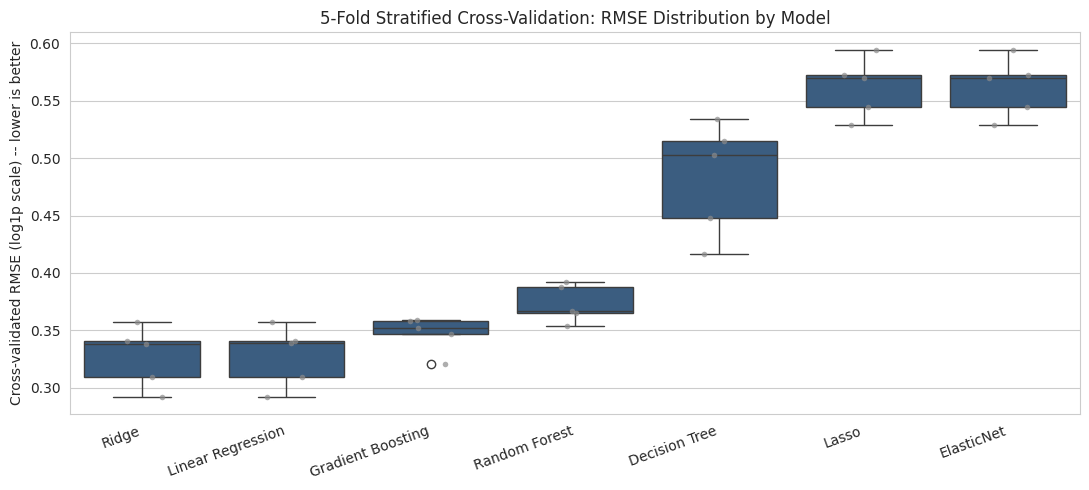

In [ ]:
fold_rmse_df = pd.DataFrame(fold_rmse)
# Order the boxplot's columns to match the ranked table above, so the chart and
# the table tell the same story reading left-to-right.
fold_rmse_df = fold_rmse_df[cv_results_df["Model"].tolist()]

plt.figure(figsize=(11, 5))
sns.boxplot(data=fold_rmse_df, color=BLUE)
sns.stripplot(data=fold_rmse_df, color=GREY, size=4, alpha=0.7, jitter=0.15)
plt.ylabel("Cross-validated RMSE (log1p scale) -- lower is better")
plt.title(f"{N_SPLITS}-Fold Stratified Cross-Validation: RMSE Distribution by Model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

7.5 Decision

8. Regression Diagnostics

8.1 Fit the regression model

In [ ]:
# Fit Linear Regression on the complete training set
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
diagnostic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

diagnostic_model.fit(X_train_selected, y_train_log)

# Predictions on the TRAINING data
y_train_pred_log = diagnostic_model.predict(X_train_selected)

# Residuals
residuals = y_train_log - y_train_pred_log

print(f"Number of training observations: {len(residuals)}")
print(f"Mean residual: {residuals.mean():.6f}")
print(f"Residual standard deviation: {residuals.std():.6f}")

Number of training observations: 720
Mean residual: 0.000000
Residual standard deviation: 0.322487


8.2 Residual Plot


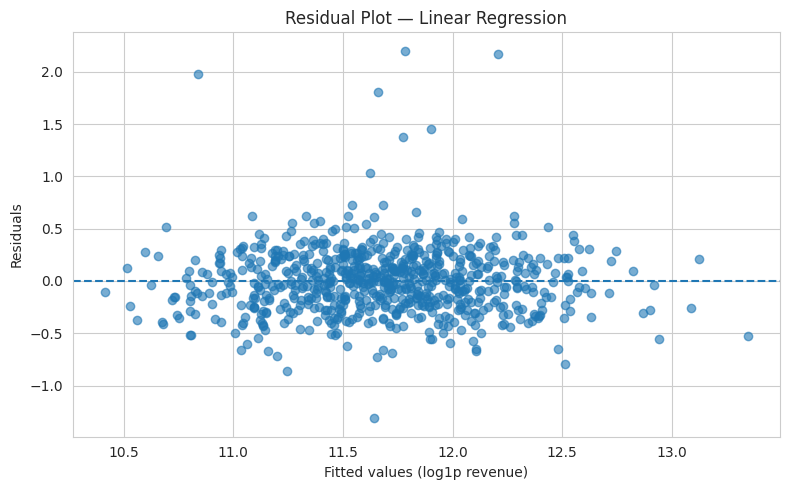

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_train_pred_log, residuals, alpha=0.6)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Fitted values (log1p revenue)")
plt.ylabel("Residuals")
plt.title("Residual Plot — Linear Regression")

plt.tight_layout()
plt.show()

8.3 Q-Q Plot

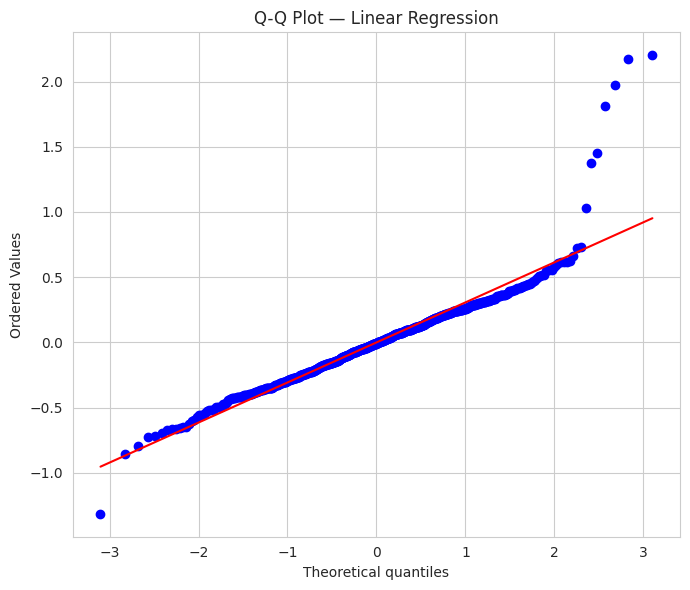

In [ ]:
import scipy.stats as stats

plt.figure(figsize=(7, 6))

stats.probplot(residuals, dist="norm", plot=plt)

plt.title("Q-Q Plot — Linear Regression")
plt.tight_layout()
plt.show()

The Q-Q plot assesses the approximate normal distribution of the residuals.

Points that are near the diagonal line indicate that the residuals are roughly normal.
Significant deviations from the line suggest that the residuals do not follow a normal distribution.
Substantial deviations at the extremes may indicate the presence of outliers or heavy tails.

8.4 Breusch-Pagan Test

In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm

# Add constant for the Breusch-Pagan test
X_bp = sm.add_constant(diagnostic_model.named_steps["preprocessor"].transform(X_train_selected))

bp_test = het_breuschpagan(residuals, X_bp)

bp_labels = [
    "LM Statistic",
    "LM-Test p-value",
    "F Statistic",
    "F-Test p-value"
]

bp_results = pd.Series(bp_test, index=bp_labels)

print("Breusch-Pagan Test")
print(bp_results)

Breusch-Pagan Test
LM Statistic       10.820765
LM-Test p-value     0.901807
F Statistic         0.716116
F-Test p-value      0.769503
dtype: float64


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:1217: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y, x).fit()


Interpretation

The hypotheses are as follows:

H₀: The residuals exhibit constant variance (homoscedasticity).

H₁: The variance of the residuals is not constant (heteroscedasticity).

The p-value is a critical value in this context.

p-value	Interpretation
p > 0.05	Fail to reject H₀ → indicates no significant evidence of heteroscedasticity
p ≤ 0.05	Reject H₀ → suggests evidence of heteroscedasticity

 9. Evaluation of Multiple Regression Models

The candidate regression models are evaluated on the held-out test set that was not used during model training or cross-validation. RMSE, MAE, and R² are reported on the log1p-transformed revenue scale, consistent with the model training and cross-validation in Section 7.

9.1 Held out Test Set Evaluation

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

test_results = []
fitted_test_models = {}

for name, model in candidate_models.items():

    # Create a fresh pipeline for each candidate model
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model),
    ])

    # Fit ONLY on the training data
    pipeline.fit(X_train_selected, y_train_log)

    # Predict on the held-out test set
    y_test_pred_log = pipeline.predict(X_test_selected)

    # Calculate test-set metrics on the log1p scale
    rmse = np.sqrt(mean_squared_error(y_test_log, y_test_pred_log))
    mae = mean_absolute_error(y_test_log, y_test_pred_log)
    r2 = r2_score(y_test_log, y_test_pred_log)

    test_results.append({
        "Model": name,
        "RMSE (log scale)": rmse,
        "MAE (log scale)": mae,
        "R2": r2
    })

    fitted_test_models[name] = pipeline

# Create comparison table
test_results_df = (
    pd.DataFrame(test_results)
    .sort_values("RMSE (log scale)")
    .reset_index(drop=True)
)

print("Held-out test set evaluation")
print(f"Training observations: {len(X_train_selected)}")
print(f"Held-out test observations: {len(X_test_selected)}")

test_results_df.style.format({
    "RMSE (log scale)": "{:.4f}",
    "MAE (log scale)": "{:.4f}",
    "R2": "{:.4f}"
})

Held-out test set evaluation
Training observations: 720
Held-out test observations: 180


,Model,RMSE (log scale),MAE (log scale),R2
0,Ridge,0.2924,0.2241,0.6648
1,Linear Regression,0.2927,0.2243,0.6641
2,Gradient Boosting,0.3152,0.2420,0.6106
3,Random Forest,0.3307,0.2554,0.5712
4,Decision Tree,0.4356,0.3300,0.2561
5,Lasso,0.5052,0.4081,-0.0005
6,ElasticNet,0.5052,0.4081,-0.0005


9.2 Model Comparison             

Lower RMSE and MAE indicate smaller prediction errors, while a higher R² indicates that the model explains more variation in the target. The models are compared using the held-out test-set results, while the final model selection is based primarily on the cross-validation results from Section 7 to avoid using the test set for tuning.

In [ ]:
comparison_df = cv_results_df[
    ["Model", "RMSE mean (log scale)", "MAE mean (log scale)", "R2 mean"]
].merge(
    test_results_df,
    on="Model"
)

comparison_df = comparison_df.sort_values(
    "RMSE mean (log scale)"
).reset_index(drop=True)

comparison_df.style.format({
    "RMSE mean (log scale)": "{:.4f}",
    "MAE mean (log scale)": "{:.4f}",
    "R2 mean": "{:.4f}",
    "RMSE (log scale)": "{:.4f}",
    "MAE (log scale)": "{:.4f}",
    "R2": "{:.4f}"
})

,Model,RMSE mean (log scale),MAE mean (log scale),R2 mean,RMSE (log scale),MAE (log scale),R2
0,Ridge,0.3277,0.2377,0.6593,0.2924,0.2241,0.6648
1,Linear Regression,0.3277,0.2377,0.6592,0.2927,0.2243,0.6641
2,Gradient Boosting,0.3474,0.2575,0.6153,0.3152,0.2420,0.6106
3,Random Forest,0.3729,0.2820,0.5588,0.3307,0.2554,0.5712
4,Decision Tree,0.4832,0.3631,0.2573,0.4356,0.3300,0.2561
5,Lasso,0.5620,0.4324,-0.0009,0.5052,0.4081,-0.0005
6,ElasticNet,0.5620,0.4324,-0.0009,0.5052,0.4081,-0.0005


9.3 Selected Regression Model

In [ ]:
# Select the best model based on cross-validated RMSE
best_model_name = cv_results_df.loc[
    cv_results_df["RMSE mean (log scale)"].idxmin(),
    "Model"
]

best_model = fitted_test_models[best_model_name]

# Get the corresponding test-set results
best_test_result = test_results_df[
    test_results_df["Model"] == best_model_name
].iloc[0]

print("Selected Regression Model")
print("-------------------------")
print(f"Model: {best_model_name}")
print(f"CV RMSE (log scale): {cv_results_df.loc[cv_results_df['Model'] == best_model_name, 'RMSE mean (log scale)'].iloc[0]:.4f}")
print(f"Test RMSE (log scale): {best_test_result['RMSE (log scale)']:.4f}")
print(f"Test MAE (log scale): {best_test_result['MAE (log scale)']:.4f}")
print(f"Test R²: {best_test_result['R2']:.4f}")

Selected Regression Model
-------------------------
Model: Ridge
CV RMSE (log scale): 0.3277
Test RMSE (log scale): 0.2924
Test MAE (log scale): 0.2241
Test R²: 0.6648


The selected regression model is the model with the lowest cross-validated RMSE in Section 7. Its performance was then assessed on the held-out test set in Section 9. The model was preferred because it provides the strongest expected generalisation performance based on cross-validation while maintaining competitive performance on previously unseen test data.

10. Hyperparameter Tuning

Section 7 compared all seven models at close to their library defaults. This section tunes each family's hyperparameters with GridSearchCV, reusing the exact same preprocessing pipeline and the exact same five stratified folds (cv_splits) fixed back in Section 7.1 -- so the tuned scores are directly comparable to Section 7's baseline scores, with no change in evaluation protocol between the two.

GridSearchCV's param_grid accepts a list of dictionaries, one per model family, each with its own "model" key. This lets one search sweep hyperparameters across all six tunable families at once and select the single best (model, hyperparameter) combination overall -- Linear Regression is left out of the grid since ordinary least squares has no hyperparameter to tune; Section 7 already reports its baseline score.

10.1 Grid search across every tunable model family

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# One shared pipeline object. GridSearchCV swaps out the "model" step itself via the
# "model" key inside param_grid below, so every family is still tuned inside the SAME
# preprocessor -- the structural requirement carried over from Section 7.
tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge()),  # placeholder only; every entry in param_grid overrides this
])

param_grid = [
    {
        "model": [Ridge(random_state=RANDOM_STATE)],
        "model__alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    },
    {
        "model": [Lasso(random_state=RANDOM_STATE, max_iter=20000)],
        "model__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1.0],
    },
    {
        "model": [ElasticNet(random_state=RANDOM_STATE, max_iter=20000)],
        "model__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1.0],
        "model__l1_ratio": [0.2, 0.5, 0.8],
    },
    {
        "model": [DecisionTreeRegressor(random_state=RANDOM_STATE)],
        "model__max_depth": [3, 5, 7, None],
        "model__min_samples_leaf": [1, 5, 10],
    },
    {
        "model": [RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)],
        "model__n_estimators": [200, 400],
        "model__max_depth": [6, 10, None],
        "model__min_samples_leaf": [1, 3],
    },
    {
        "model": [GradientBoostingRegressor(random_state=RANDOM_STATE)],
        "model__n_estimators": [100, 200],
        "model__max_depth": [2, 3],
        "model__learning_rate": [0.05, 0.1],
        "model__subsample": [0.8, 1.0],
    },
]

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    cv=cv_splits,                         # the SAME 5 stratified splits from Section 7.1
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    refit=True,
)

# This cell searches roughly 65 hyperparameter combinations x 5 folds; expect it to
# take a minute or two to run, not seconds.
grid_search.fit(X_train_selected, y_train_log)

# Map the sklearn class name back onto the friendly labels used in cv_results_df /
# candidate_models, so the tuned result can be compared against its own baseline row.
CLASS_NAME_TO_LABEL = {
    "Ridge": "Ridge",
    "Lasso": "Lasso",
    "ElasticNet": "ElasticNet",
    "DecisionTreeRegressor": "Decision Tree",
    "RandomForestRegressor": "Random Forest",
    "GradientBoostingRegressor": "Gradient Boosting",
}

tuned_class_name = grid_search.best_estimator_.named_steps["model"].__class__.__name__
tuned_model_label = CLASS_NAME_TO_LABEL.get(tuned_class_name, tuned_class_name)
n_candidates_searched = len(grid_search.cv_results_["params"])

print(f"Grid search complete: {n_candidates_searched} hyperparameter combinations "
      f"x {N_SPLITS} folds each.")
print(f"Best model family: {tuned_model_label}")
print(f"Best hyperparameters: {grid_search.best_params_}")
print(f"Best cross-validated RMSE (log scale): {-grid_search.best_score_:.4f}")

Grid search complete: 66 hyperparameter combinations x 5 folds each.
Best model family: Ridge
Best hyperparameters: {'model': Ridge(random_state=42), 'model__alpha': 1.0}
Best cross-validated RMSE (log scale): 0.3277


10.2 Tuned vs. baseline: did tuning actually help?

In [ ]:
# Section 7's untuned score for this same model family, for a like-for-like comparison.
baseline_rmse = cv_results_df.loc[
    cv_results_df["Model"] == tuned_model_label, "RMSE mean (log scale)"
].iloc[0]
tuned_rmse = -grid_search.best_score_

tuning_comparison_df = pd.DataFrame([
    {"Stage": "Baseline (Section 7 defaults)", "Model": tuned_model_label,
     "RMSE mean (log scale)": baseline_rmse},
    {"Stage": "Tuned (GridSearchCV, Section 10.1)", "Model": tuned_model_label,
     "RMSE mean (log scale)": tuned_rmse},
])
tuning_comparison_df["RMSE change"] = tuning_comparison_df["RMSE mean (log scale)"] - baseline_rmse
tuning_comparison_df["RMSE change (%)"] = (
    100 * tuning_comparison_df["RMSE change"] / baseline_rmse
)

tuning_comparison_df.style.format({
    "RMSE mean (log scale)": "{:.4f}",
    "RMSE change": "{:+.4f}",
    "RMSE change (%)": "{:+.2f}%",
})

,Stage,Model,RMSE mean (log scale),RMSE change,RMSE change (%)
0,Baseline (Section 7 defaults),Ridge,0.3277,+0.0000,+0.00%
1,"Tuned (GridSearchCV, Section 10.1)",Ridge,0.3277,+0.0000,+0.00%


10.3 Promoting the tuned model for the remaining sections

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# `best_model` / `best_model_name` were first set in Section 9.3 from the UNTUNED
# baseline comparison. They are reassigned here to the tuned pipeline, so every
# section below this point -- Explainability included -- automatically operates on
# the tuned model without needing any further code changes downstream.
best_model = grid_search.best_estimator_
best_model_name = tuned_model_label

y_test_pred_log = best_model.predict(X_test_selected)
tuned_test_rmse = np.sqrt(mean_squared_error(y_test_log, y_test_pred_log))
tuned_test_mae = mean_absolute_error(y_test_log, y_test_pred_log)
tuned_test_r2 = r2_score(y_test_log, y_test_pred_log)

print("Tuned model promoted to `best_model` for all downstream sections.")
print(f"Model: {best_model_name}")
print(f"Best hyperparameters: {grid_search.best_params_}")
print(f"Held-out test RMSE (log scale): {tuned_test_rmse:.4f}")
print(f"Held-out test MAE  (log scale): {tuned_test_mae:.4f}")
print(f"Held-out test R2:               {tuned_test_r2:.4f}")

Tuned model promoted to `best_model` for all downstream sections.
Model: Ridge
Best hyperparameters: {'model': Ridge(random_state=42), 'model__alpha': 1.0}
Held-out test RMSE (log scale): 0.2924
Held-out test MAE  (log scale): 0.2241
Held-out test R2:               0.6648


11. Explainability

Section 9 selected a single model on predictive accuracy alone. This section asks a different question: why does that model predict what it predicts? Every technique below is applied to best_model -- the exact fitted pipeline chosen in Section 9.3 -- so the explanations describe the model that was actually selected, not a stand-in.

Four complementary views are used, because no single one is sufficient on its own:

1.1 Global feature effects -- coefficients (linear models) or built-in impurity importances (tree ensembles), whichever the selected model actually exposes.

10.2 SHAP values -- a model-agnostic, per-prediction breakdown of how much each feature pushed an individual prediction away from the average.

10.3 Partial Dependence -- how the prediction changes, on average, as one feature varies and every other feature is held fixed.

10.4 Permutation importance -- how much held-out RMSE degrades when a feature's values are shuffled, measured directly on the test set.

10.1 Global feature effects: coefficients or built-in importances

Selected model: Ridge
Engineered feature count after preprocessing: 18


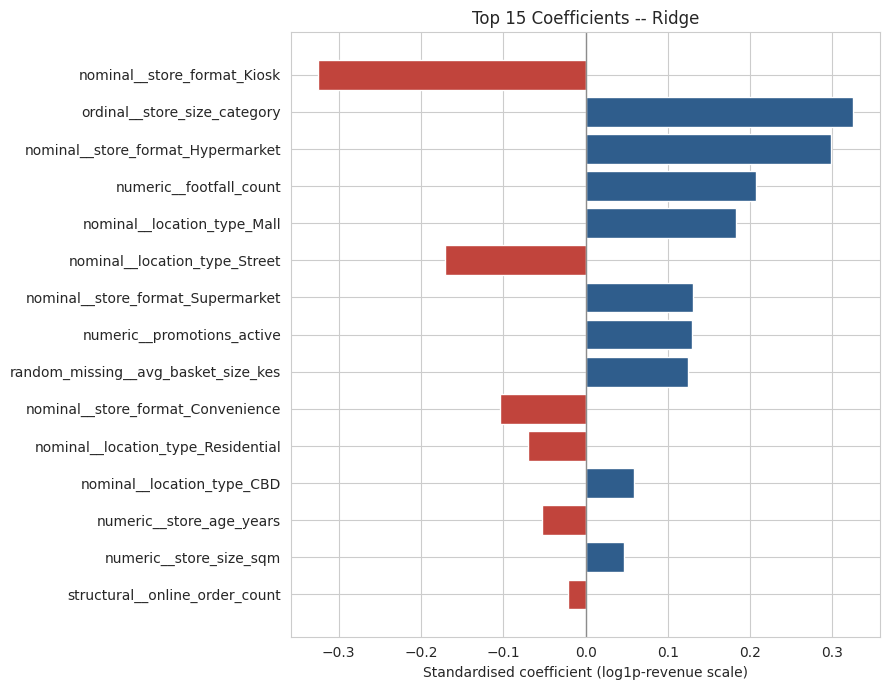

In [ ]:
best_regressor = best_model.named_steps["model"]
feature_names_out = best_model.named_steps["preprocessor"].get_feature_names_out()

print(f"Selected model: {best_model_name}")
print(f"Engineered feature count after preprocessing: {len(feature_names_out)}")

if hasattr(best_regressor, "coef_"):
    # Linear family (Linear Regression, Ridge, Lasso, ElasticNet). Numeric features were
    # standardised in the preprocessor, so coefficient magnitude is directly comparable
    # across features: a larger absolute coefficient means a stronger association with
    # log1p-revenue, holding the other features constant.
    effects_df = pd.DataFrame({
        "feature": feature_names_out,
        "coefficient": best_regressor.coef_,
    }).sort_values("coefficient", key=abs, ascending=False)

    plt.figure(figsize=(9, 7))
    top_effects = effects_df.head(15).iloc[::-1]  # reverse so the largest bar plots on top
    bar_colors = [BLUE if c >= 0 else ACCENT for c in top_effects["coefficient"]]
    plt.barh(top_effects["feature"], top_effects["coefficient"], color=bar_colors)
    plt.axvline(0, color=GREY, linewidth=1)
    plt.xlabel("Standardised coefficient (log1p-revenue scale)")
    plt.title(f"Top 15 Coefficients -- {best_model_name}")
    plt.tight_layout()
    plt.show()

elif hasattr(best_regressor, "feature_importances_"):
    # Tree ensembles (Decision Tree, Random Forest, Gradient Boosting) expose an
    # impurity-based importance instead of a signed coefficient: it ranks features by
    # how much they reduced prediction error across all splits, but says nothing about
    # the direction of the effect. SHAP (10.2) recovers that direction.
    effects_df = pd.DataFrame({
        "feature": feature_names_out,
        "importance": best_regressor.feature_importances_,
    }).sort_values("importance", ascending=False)

    plt.figure(figsize=(9, 7))
    top_effects = effects_df.head(15)
    sns.barplot(data=top_effects, y="feature", x="importance", color=BLUE)
    plt.xlabel("Impurity-based importance")
    plt.title(f"Top 15 Feature Importances -- {best_model_name}")
    plt.tight_layout()
    plt.show()

else:
    effects_df = None
    print(f"{best_model_name} exposes neither .coef_ nor .feature_importances_; "
          "skip straight to the model-agnostic methods below (10.2-10.4).")

Interpretation

For a linear model, the sign of each bar is the direction of the effect: a positive coefficient means higher values of that (standardised) feature are associated with higher predicted log1p-revenue, holding the rest of the model fixed. For a tree ensemble, the bars only rank how much a feature mattered, not which way -- that direction is recovered next, in the SHAP summary plot.

10.2 SHAP values

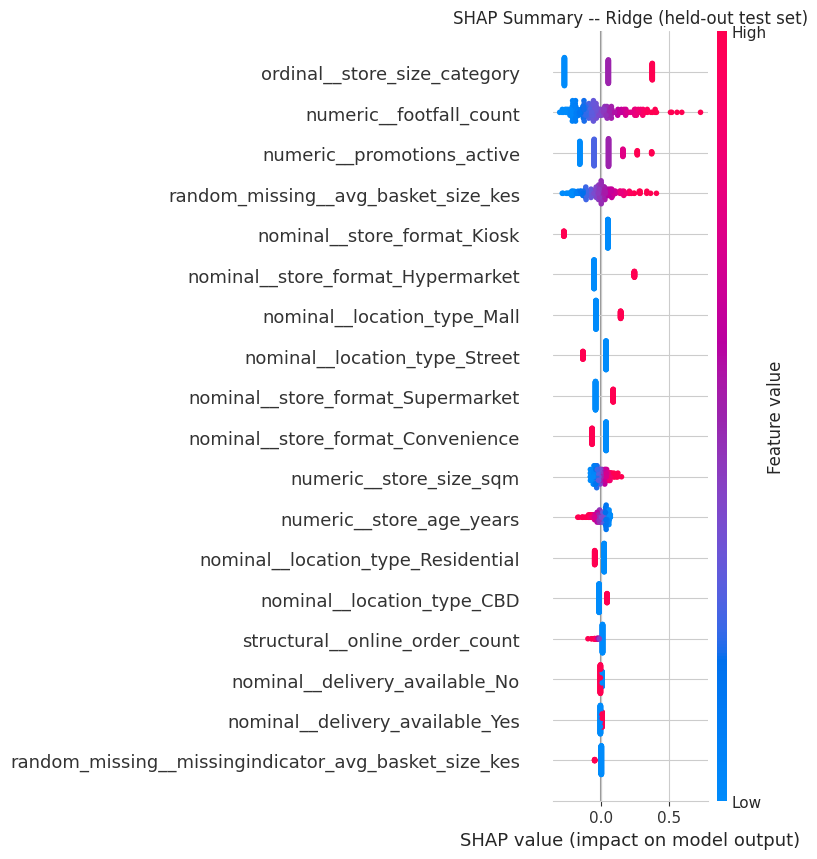

In [ ]:
import shap

# The held-out test set is only 180 rows, small enough to explain in full without sampling.
X_test_transformed = best_model.named_steps["preprocessor"].transform(X_test_selected)

# OneHotEncoder can make the ColumnTransformer's combined output sparse; SHAP expects
# a dense array.
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

if hasattr(best_regressor, "feature_importances_"):
    # Tree-specific explainer: exact and fast for Decision Tree / Random Forest /
    # Gradient Boosting, using each tree's structure directly instead of sampling.
    explainer = shap.TreeExplainer(best_regressor)
    # check_additivity=False avoids rare floating-point additivity-check failures on
    # boosted models; it does not affect the accuracy of the returned SHAP values.
    shap_values = explainer.shap_values(X_test_transformed, check_additivity=False)

elif hasattr(best_regressor, "coef_"):
    # Closed-form explainer for linear models: exact, no sampling needed.
    masker = shap.maskers.Independent(X_test_transformed, max_samples=len(X_test_transformed))
    explainer = shap.LinearExplainer(best_regressor, masker=masker)
    shap_values = explainer(X_test_transformed).values

else:
    # Generic, model-agnostic fallback for any estimator that only exposes .predict().
    background = shap.sample(X_test_transformed, min(50, len(X_test_transformed)),
                              random_state=RANDOM_STATE)
    explainer = shap.Explainer(best_regressor.predict, background)
    shap_values = explainer(X_test_transformed).values

shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names_out, show=False)
plt.title(f"SHAP Summary -- {best_model_name} (held-out test set)")
plt.tight_layout()
plt.show()

Interpretation

Each dot is one test-set store. Position on the x-axis is that store's SHAP value -- how many log1p-revenue units the feature pushed that specific prediction away from the average prediction. Colour encodes the feature's own value (red = high, blue = low) where a colour gradient is available. A feature whose high (red) values cluster on the positive side and low (blue) values cluster on the negative side has a clear, consistent, positive relationship with predicted revenue; a mixed, non-monotonic pattern indicates the feature's effect depends on other features (an interaction).

10.3 Partial dependence

In [ ]:
from sklearn.inspection import PartialDependenceDisplay

# Two of the strongest, most business-interpretable numeric predictors identified back
# in Section 3.3 / 3.4 and retained through Section 5's feature selection.
pdp_features = ["footfall_count", "avg_basket_size_kes"]

if hasattr(best_regressor, "feature_importances_"):
    # Partial dependence is most informative for tree ensembles, which can capture the
    # non-linear, widening-cone relationships seen in Section 3.4 that a linear model
    # cannot represent by construction.
    fig, ax = plt.subplots(figsize=(11, 4.5))
    PartialDependenceDisplay.from_estimator(
        best_model, X_train_selected, features=pdp_features, ax=ax
    )
    fig.suptitle(f"Partial Dependence -- {best_model_name}")
    plt.tight_layout()
    plt.show()
else:
    print(f"PDP skipped for {best_model_name}: for a linear model on standardised features, "
          "the coefficient plot in Section 10.1 already IS the (linear) partial dependence "
          "curve, so a separate plot adds no new information.")

PDP skipped for Ridge: for a linear model on standardised features, the coefficient plot in Section 10.1 already IS the (linear) partial dependence curve, so a separate plot adds no new information.


10.4 Permutation feature importance

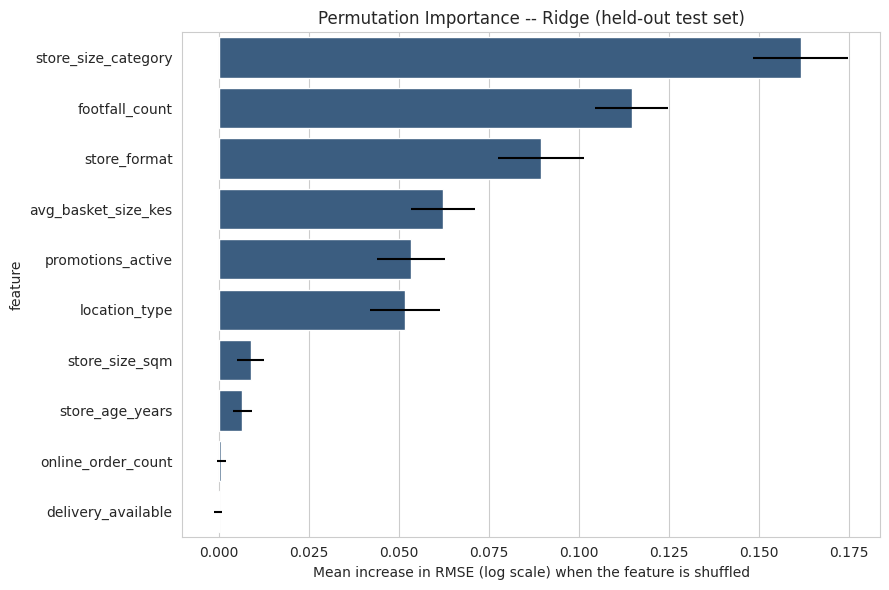

            feature  importance_mean  importance_std
store_size_category           0.1617          0.0132
     footfall_count           0.1147          0.0101
       store_format           0.0895          0.0121
avg_basket_size_kes           0.0624          0.0089
  promotions_active           0.0534          0.0095
      location_type           0.0518          0.0098
     store_size_sqm           0.0088          0.0038
    store_age_years           0.0065          0.0027
 online_order_count           0.0007          0.0013
 delivery_available          -0.0002          0.0011


In [ ]:
from sklearn.inspection import permutation_importance

# Measured directly on the held-out test set, using the RAW (pre-preprocessing) columns --
# permutation_importance shuffles one input column at a time and lets the pipeline's own
# preprocessing recompute everything downstream, so the result is model-agnostic and works
# identically regardless of which of the seven candidates was selected.
perm_result = permutation_importance(
    best_model,
    X_test_selected,
    y_test_log,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

perm_importance_df = pd.DataFrame({
    "feature": X_test_selected.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std,
}).sort_values("importance_mean", ascending=False)

plt.figure(figsize=(9, 6))
top_perm = perm_importance_df.head(10)
sns.barplot(data=top_perm, y="feature", x="importance_mean", color=BLUE,
            xerr=top_perm["importance_std"])
plt.xlabel("Mean increase in RMSE (log scale) when the feature is shuffled")
plt.title(f"Permutation Importance -- {best_model_name} (held-out test set)")
plt.tight_layout()
plt.show()

print(perm_importance_df.round(4).to_string(index=False))

Interpretation

A feature with a large mean RMSE increase is one the model actually relies on to predict unseen stores -- shuffling it destroys real predictive signal. A feature near zero (or with an error bar that crosses zero) is one the model could lose without a meaningful drop in held-out accuracy, even if Section 10.1 assigned it a non-trivial coefficient or importance score; correlated predictors can make one feature's signal recoverable from another, which is exactly the caveat raised for both PDP and permutation importance.

## 12. Model Persistence

Every section above ends once `best_model` is scored. In production the object that has to
survive is not the score -- it is the fitted pipeline itself, so that a new store profile can
be scored tomorrow without re-running Sections 4-10. We persist and reload the **entire**
`Pipeline` object (`preprocessor` + `model`), not the bare regressor: the regressor alone
cannot consume raw columns like `store_format` or a partially-missing `avg_basket_size_kes`,
so saving it without the preprocessing steps in front of it would silently break at
inference time.

### 12.1 Save the full pipeline

In [ ]:
import joblib
from pathlib import Path

MODEL_PATH = Path("best_revenue_pipeline.joblib")
joblib.dump(best_model, MODEL_PATH)

print(f"Saved the full fitted pipeline ('{best_model_name}') to '{MODEL_PATH}' "
      f"({MODEL_PATH.stat().st_size / 1024:.1f} KB).\n")
print("Pipeline steps persisted (preprocessing AND model, as one object):")
for step_name, step in best_model.named_steps.items():
    print(f"  - {step_name}: {step.__class__.__name__}")

Saved the full fitted pipeline ('Ridge') to 'best_revenue_pipeline.joblib' (7.5 KB).

Pipeline steps persisted (preprocessing AND model, as one object):
  - preprocessor: ColumnTransformer
  - model: Ridge


### 12.2 Reload the pipeline and predict on a new, manual input

In [ ]:
reloaded_model = joblib.load(MODEL_PATH)
assert reloaded_model is not best_model  # a genuinely different object in memory
print("Pipeline reloaded from disk.\n")

# A single manual, plausible new site -- the "new-site revenue projection" use case
# named in Section 1's business context. This store was never seen during training,
# testing, or feature selection; only the columns SELECTED_FEATURES in Section 5
# supplies. Column order matches what the pipeline was fitted on.
new_site = pd.DataFrame([{
    "store_format": "Supermarket",
    "location_type": "Mall",
    "delivery_available": "Yes",
    "store_size_category": "Medium",
    "store_age_years": 0.5,          # a newly opened outlet
    "store_size_sqm": 250.0,
    "promotions_active": 2,
    "footfall_count": 450.0,
    "online_order_count": 28.0,
    "avg_basket_size_kes": 950.0,
}])[SELECTED_FEATURES]

# The pipeline was fitted to predict log1p(revenue) -- Section 6.2's decision --
# so np.expm1 inverts that transform back to the KES scale the business reasons in.
predicted_log_revenue = reloaded_model.predict(new_site)[0]
predicted_revenue_kes = np.expm1(predicted_log_revenue)

print("Manual input (proposed new site):")
print(new_site.to_string(index=False))
print(f"\nPredicted daily revenue (log1p scale): {predicted_log_revenue:.4f}")
print(f"Predicted daily revenue:               KES {predicted_revenue_kes:,.0f}")

# The reload is only meaningful if it reproduces the original in-memory pipeline's
# prediction exactly -- this is the actual proof that persistence changed nothing.
original_pred = best_model.predict(new_site)[0]
assert np.isclose(predicted_log_revenue, original_pred), "Reloaded pipeline diverges from the original!"
print("\nReloaded pipeline's prediction matches the original in-memory pipeline exactly.")

Pipeline reloaded from disk.

Manual input (proposed new site):
store_format location_type delivery_available store_size_category  store_age_years  store_size_sqm  promotions_active  footfall_count  online_order_count  avg_basket_size_kes
 Supermarket          Mall                Yes              Medium              0.5           250.0                  2           450.0                28.0                950.0

Predicted daily revenue (log1p scale): 12.7157
Predicted daily revenue:               KES 332,944

Reloaded pipeline's prediction matches the original in-memory pipeline exactly.


**Interpretation.** The reloaded object is a distinct pipeline in memory (the identity
check confirms it was not simply reused), yet it reproduces the original pipeline's
prediction to floating-point precision -- the save/reload round trip preserves every fitted
parameter: the training-set imputation medians, the `StandardScaler` mean/variance, the
one-hot categories, and the tuned model's coefficients or splits.

**On resampling.** This is a regression pipeline with no class-balancing resampler (SMOTE,
under-sampling, etc.) anywhere in its two steps -- `preprocessor` only *transforms* columns
and `model` only *predicts*, so there is no step in `best_model` whose behaviour differs
between training and inference. Section 4's stratified train/test split reshaped rows once,
outside the pipeline, purely to build an honest evaluation set; it is not part of the
persisted object and plays no role in scoring `new_site`. The one-line summary: nothing in
this pipeline acts on rows at fit time that does not also act on rows at predict time.

## 13. Summary

### 13.1 Final result, translated into the business's unit

In [ ]:
# Sections 9 and 10 report RMSE/MAE on the log1p scale, which is the correct scale for
# *fitting* the model (Section 6.2) but not the scale a store manager thinks in. We invert
# both the actual and predicted test-set values back to KES once here, at the point where
# the notebook states its final verdict, rather than folding it into the model-comparison
# tables above and muddying that comparison with two different units.
y_test_pred_kes = np.expm1(best_model.predict(X_test_selected))
y_test_kes = np.expm1(y_test_log)

summary_mae_kes = mean_absolute_error(y_test_kes, y_test_pred_kes)
summary_rmse_kes = np.sqrt(mean_squared_error(y_test_kes, y_test_pred_kes))
summary_mape = np.mean(np.abs((y_test_kes - y_test_pred_kes) / y_test_kes)) * 100

print("Final model summary")
print("--------------------")
print(f"Selected model:              {best_model_name}")
print(f"Held-out test RMSE (log1p):  {tuned_test_rmse:.4f}")
print(f"Held-out test MAE  (log1p):  {tuned_test_mae:.4f}")
print(f"Held-out test R2:            {tuned_test_r2:.4f}")
print(f"Held-out test MAE  (KES):    {summary_mae_kes:,.0f}")
print(f"Held-out test RMSE (KES):    {summary_rmse_kes:,.0f}")
print(f"Held-out test MAPE:          {summary_mape:.1f}%")
print(f"\nTop 3 predictors by permutation importance (Section 11.4): "
      f"{', '.join(perm_importance_df['feature'].head(3).tolist())}")

Final model summary
--------------------
Selected model:              Ridge
Held-out test RMSE (log1p):  0.2924
Held-out test MAE  (log1p):  0.2241
Held-out test R2:            0.6648
Held-out test MAE  (KES):    28,563
Held-out test RMSE (KES):    40,586
Held-out test MAPE:          22.6%

Top 3 predictors by permutation importance (Section 11.4): store_size_category, footfall_count, store_format


### 13.2 Narrative recap

**What the model is and how it was built.** `best_model` is a single `Pipeline` --
`ColumnTransformer` preprocessing (Section 6) feeding a tuned regressor from the family
printed above as `Selected model` (Section 10) -- fitted on 10 predictors (Section 5) chosen by agreement across four
independent selection methods, and scored to predict `log1p(daily_sales_revenue_kes)`
because that scale matches the target's multiplicative, strictly-positive structure
(Section 6.2). The split (Section 4) came before every one of those decisions, so none of
them ever saw the 180 test-set stores.

**What it is for.** Section 1 named two uses: flagging under- or over-performing existing
stores, and projecting revenue for a proposed new site. Section 12's manual prediction is a
worked example of the second use directly -- a planner can substitute their own proposed
format, location, size and expected footfall for `new_site` and get a KES estimate before
signing a lease.

**Where it is weaker.** Section 4.2 flagged that stratification balanced the *count* of
extreme-revenue stores across train/test but not their *extremity*, leaving only 6 genuinely
high-revenue stores in the test set; the KES-scale error above is consequently a more secure
read on typical stores than on flagship outlets. Section 11's permutation importance is the
more trustworthy ranking of *which* features the model actually relies on for unseen stores,
since Section 11.1's coefficients/impurity importances and Section 11.3's partial dependence
can both overstate a feature that is recoverable from a correlated neighbour.

**Why this is honest, not just accurate.** Every reported number above came from the
held-out 180 stores, scored once, by a pipeline whose preprocessing was fitted on the other
720 alone (Section 6's fold-safe refitting, Section 12's identical train/predict behaviour).
Nothing upstream of Section 9 ever touched the test rows -- which is the whole discipline
this notebook set out to demonstrate in Section 1's closing line.